## Project Objectives: OpenFlights Bipartite Network Analysis

**Main Objective**

My goal is to analyze the OpenFlights airline–airport network to understand connectivity patterns, identify important airlines and airports, and discover how groups of airlines and airports are connected through their route relationships.

**Specific Objectives**

- **Data Preparation:** Clean and integrate the OpenFlights airlines, airports, and routes datasets to create a reliable dataset for network analysis.

- **Bipartite Network Construction:** Build a bipartite network where airlines and airports represent two types of nodes, and edges represent their relationships.

- **Degree Centrality Analysis:** Identify airlines connected to the most airports and airports served by the most airlines to understand their importance within the network.

- **Edge Weight Analysis:** Calculate the number of distinct recorded routes associated with each airline–airport relationship to identify relationships with greater route diversity.

- **Exploratory Data Analysis:** Examine degree and edge weight distributions using descriptive statistics and visualizations to identify connectivity patterns and differences across the network.

- **Island Method:** Apply different edge weight thresholds to identify which airlines and airports remain connected as lower-weight relationships are removed, and examine how the network separates into distinct groups.

- **Island Characteristics Analysis:** Investigate the airlines and airports within the major islands, compare their connectivity patterns, and explore what distinguishes one group from another.

- **Data Visualization and Interpretation:** Use network visualizations, charts, and summary statistics to communicate findings and explain the structure of the airline network.

**Expected Outcome**

Through this project, I aim to identify highly connected airlines and airport hubs, understand how route diversity is distributed, and discover meaningful groups within the airline network. My analysis will demonstrate data cleaning, data transformation, exploratory data analysis, network analysis, visualization, and data-driven interpretation skills.

# Airlines Dataset (airlines.dat)

Purpose: This file is my directory of airline companies.

Key Information: It records the official name of the carrier, their home country, active status, and industry codes (IATA/ICAO).

Network Role (Group 1 Nodes): In my bimodal graph, these represent my first distinct group.

Columns:

Airline ID: The unique numerical identifier for the airline.

Name: The corporate name of the airline.

Alias: Alternative names (often \N for none).

IATA / ICAO: Standard 2-letter and 3-letter industry codes.

Callsign: The identifier pilots use over the radio.

Country: The country where the airline is headquartered.

Active: "Y" if the airline is operating, "N" if defunct.

# Airports Dataset (airports.dat)

Purpose: This file lists the physical airports worldwide.

Key Information: It includes the airport's name, city, country, IATA code, and geographic coordinates.

Network Role (Group 2 Nodes): In my bimodal graph, these represent my second distinct group.

Columns:

Airport ID: The unique numerical identifier for the airport.

Name / City / Country: The name and location of the airport.

IATA / ICAO: Standard 3-letter and 4-letter industry codes.

#  Routes Dataset (routes.dat)

Purpose: This file is my master schedule mapping the flight paths.

Key Information: Every row represents a commercial flight path, detailing the airline, departure airport, arrival airport, and aircraft type.

Network Role (The Edges): This dataset provides the connections between my two groups by matching an Airline ID to a Source Airport ID.

Columns:

Airline / Airline ID: The carrier code and unique ID.

Source Airport / Source Airport ID: The departure airport code and unique ID.

Destination Airport / Destination Airport ID: The arrival airport code and unique ID.

Codeshare: "Y" if operated by a partner airline, empty otherwise.

Stops: Number of layovers.

Equipment: 3-letter code for the plane type.

In [2]:
import pandas as pd

# Define the raw GitHub URLs for the OpenFlights data
routes_url = "https://raw.githubusercontent.com/jpatokal/openflights/master/data/routes.dat"
airports_url = "https://raw.githubusercontent.com/jpatokal/openflights/master/data/airports.dat"
airlines_url = "https://raw.githubusercontent.com/jpatokal/openflights/master/data/airlines.dat"

# The original .dat files do not contain column headers, so we assign them manually
# based on the OpenFlights documentation so the data makes sense when you read it.

routes_cols = ['Airline', 'Airline ID', 'Source Airport', 'Source Airport ID',
               'Destination Airport', 'Destination Airport ID', 'Codeshare', 'Stops', 'Equipment']
routes_df = pd.read_csv(routes_url, header=None, names=routes_cols)

airports_cols = ['Airport ID', 'Name', 'City', 'Country', 'IATA', 'ICAO',
                 'Latitude', 'Longitude', 'Altitude', 'Timezone', 'DST', 'Tz_database', 'Type', 'Source']
airports_df = pd.read_csv(airports_url, header=None, names=airports_cols)

airlines_cols = ['Airline ID', 'Name', 'Alias', 'IATA', 'ICAO', 'Callsign', 'Country', 'Active']
airlines_df = pd.read_csv(airlines_url, header=None, names=airlines_cols)

# Display the first 3 rows of each dataset to understand the structure
print("=== ROUTES DATA ===")
display(routes_df.head(3))

print("\n=== AIRPORTS DATA ===")
display(airports_df.head(3))

print("\n=== AIRLINES DATA ===")
display(airlines_df.head(3))

=== ROUTES DATA ===


,Airline,Airline ID,Source Airport,Source Airport ID,Destination Airport,Destination Airport ID,Codeshare,Stops,Equipment
0,2B,410,AER,2965,KZN,2990,NaN,0,CR2
1,2B,410,ASF,2966,KZN,2990,NaN,0,CR2
2,2B,410,ASF,2966,MRV,2962,NaN,0,CR2



=== AIRPORTS DATA ===


,Airport ID,Name,City,Country,IATA,ICAO,Latitude,Longitude,Altitude,Timezone,DST,Tz_database,Type,Source
0,1,Goroka Airport,Goroka,Papua New Guinea,GKA,AYGA,-6.08169,145.391998,5282,10,U,Pacific/Port_Moresby,airport,OurAirports
1,2,Madang Airport,Madang,Papua New Guinea,MAG,AYMD,-5.20708,145.789001,20,10,U,Pacific/Port_Moresby,airport,OurAirports
2,3,Mount Hagen Kagamuga Airport,Mount Hagen,Papua New Guinea,HGU,AYMH,-5.82679,144.296005,5388,10,U,Pacific/Port_Moresby,airport,OurAirports



=== AIRLINES DATA ===


,Airline ID,Name,Alias,IATA,ICAO,Callsign,Country,Active
0,-1,Unknown,\N,-,NaN,\N,\N,Y
1,1,Private flight,\N,-,NaN,NaN,NaN,Y
2,2,135 Airways,\N,NaN,GNL,GENERAL,United States,N


# Description of the Datasets

Before building our bipartite network, we need to understand:
- How many airline records are available?
- How many airport records are available?
- How many routes are recorded?
- Are there missing values that could affect our network analysis?



Objective: I will examine the size and structure of the OpenFlights datasets.



Methodology: I will identify missing values, duplicate records, and potential data-quality issues before constructing the bipartite network.



Analysis: I will investigate relationships between airlines and airports using route data.



Interpretation: My findings will help me understand the connectivity patterns between the two distinct groups.



Conclusion: I will summarize the network structure, apply the island method, and evaluate the characteristics of each group.

# Exploratory Data Analysis:

I examined three OpenFlights datasets to understand their size and data quality.

- **Routes:** 67,663 records describing airline routes between airports.

- **Airports:** 7,698 records containing airport information, including location and geographic coordinates.

- **Airlines:** 6,162 records containing airline information, including company name, country, and operating status.

**Missing Values:**

- The Routes dataset contains 53,066 missing Codeshare values and 18 missing Equipment values.
- The Airports dataset contains 49 missing City values.
- The Airlines dataset contains missing values in several descriptive fields, including IATA, Callsign, Alias, and Country.

**Key Finding:**

I determined that the datasets are sufficiently large for my bipartite network analysis. I will focus on airline IDs and airport IDs because these identifiers are essential for establishing relationships between the two groups.

I will also examine missing identifiers represented by `\N`, which may not appear in the initial missing-value counts.

# Select Relevant Columns from Each Dataset
Objective
I will select only the columns needed to construct my airline–airport bipartite network and analyze the characteristics of each group.

In [3]:
# Select relevant fields from the Airlines dataset
airlines_selected = airlines_df[
    ['Airline ID',
     'Name',
     'IATA',
     'ICAO',
     'Country',
     'Active']
].copy()

# Select relevant fields from the Airports dataset
airports_selected = airports_df[
    ['Airport ID',
     'Name',
     'City',
     'Country',
     'IATA',
     'ICAO',
     'Latitude',
     'Longitude']
].copy()

# Select relevant fields from the Routes dataset
routes_selected = routes_df[
    ['Airline',
     'Airline ID',
     'Source Airport',
     'Source Airport ID',
     'Destination Airport',
     'Destination Airport ID']
].copy()

# Display selected datasets
print("=== SELECTED AIRLINES DATA ===")
display(airlines_selected.head())

print("\n=== SELECTED AIRPORTS DATA ===")
display(airports_selected.head())

print("\n=== SELECTED ROUTES DATA ===")
display(routes_selected.head())

# Check dataset dimensions
print("\n=== SELECTED DATASET DIMENSIONS ===")
print("Airlines:", airlines_selected.shape)
print("Airports:", airports_selected.shape)
print("Routes:", routes_selected.shape)

=== SELECTED AIRLINES DATA ===


,Airline ID,Name,IATA,ICAO,Country,Active
0,-1,Unknown,-,NaN,\N,Y
1,1,Private flight,-,NaN,NaN,Y
2,2,135 Airways,NaN,GNL,United States,N
3,3,1Time Airline,1T,RNX,South Africa,Y
4,4,2 Sqn No 1 Elementary Flying Training School,NaN,WYT,United Kingdom,N



=== SELECTED AIRPORTS DATA ===


,Airport ID,Name,City,Country,IATA,ICAO,Latitude,Longitude
0,1,Goroka Airport,Goroka,Papua New Guinea,GKA,AYGA,-6.081690,145.391998
1,2,Madang Airport,Madang,Papua New Guinea,MAG,AYMD,-5.207080,145.789001
2,3,Mount Hagen Kagamuga Airport,Mount Hagen,Papua New Guinea,HGU,AYMH,-5.826790,144.296005
3,4,Nadzab Airport,Nadzab,Papua New Guinea,LAE,AYNZ,-6.569803,146.725977
4,5,Port Moresby Jacksons International Airport,Port Moresby,Papua New Guinea,POM,AYPY,-9.443380,147.220001



=== SELECTED ROUTES DATA ===


,Airline,Airline ID,Source Airport,Source Airport ID,Destination Airport,Destination Airport ID
0,2B,410,AER,2965,KZN,2990
1,2B,410,ASF,2966,KZN,2990
2,2B,410,ASF,2966,MRV,2962
3,2B,410,CEK,2968,KZN,2990
4,2B,410,CEK,2968,OVB,4078



=== SELECTED DATASET DIMENSIONS ===
Airlines: (6162, 6)
Airports: (7698, 8)
Routes: (67663, 6)


# Data Type and Missing Value Validation

I examined the data types and missing values in my three selected OpenFlights datasets.

I evaluated both standard null values (NaN) and the `\N` placeholders used by OpenFlights to represent missing information.

I also reviewed the expected data types for each column. Airline and airport identifiers should be numeric, geographic coordinates should be numeric, and descriptive attributes should be stored as strings.

This validation will help me identify data-quality issues before cleaning and merging the datasets to construct my bipartite network.

In [4]:
# Define selected datasets
datasets = {
    "Airlines": airlines_selected,
    "Airports": airports_selected,
    "Routes": routes_selected
}

# Examine data types and missing values
for name, df in datasets.items():

    print(f"\n=== {name.upper()} DATASET ===")

    # Identify missing values represented by \N
    missing_placeholder = (
        df.astype("string").eq(r"\N").fillna(False)
    )

    # Create summary table
    summary = pd.DataFrame({
        "Data Type": df.dtypes.astype(str),
        "Null (NaN)": df.isna().sum(),
        "Missing (\\N)": missing_placeholder.sum(),
        "Total Missing": (
            df.isna() | missing_placeholder
        ).sum()
    })

    display(summary)


=== AIRLINES DATASET ===


,Data Type,Null (NaN),Missing (\N),Total Missing
Airline ID,int64,0,0,0
Name,object,0,0,0
IATA,object,4627,1,4628
ICAO,object,87,188,275
Country,object,15,3,18
Active,object,0,0,0



=== AIRPORTS DATASET ===


,Data Type,Null (NaN),Missing (\N),Total Missing
Airport ID,int64,0,0,0
Name,object,0,0,0
City,object,49,0,49
Country,object,0,0,0
IATA,object,0,1626,1626
ICAO,object,0,1,1
Latitude,float64,0,0,0
Longitude,float64,0,0,0



=== ROUTES DATASET ===


,Data Type,Null (NaN),Missing (\N),Total Missing
Airline,object,0,0,0
Airline ID,object,0,479,479
Source Airport,object,0,0,0
Source Airport ID,object,0,220,220
Destination Airport,object,0,0,0
Destination Airport ID,object,0,221,221


Investigating missing records

In [5]:
# Filter routes with missing Airline IDs (\N)
missing_airline_ids = routes_selected[
    routes_selected['Airline ID'] == r'\N'
]

# Display records
print("Total records with missing Airline IDs:", len(missing_airline_ids))

display(missing_airline_ids)

Total records with missing Airline IDs: 479


,Airline,Airline ID,Source Airport,Source Airport ID,Destination Airport,Destination Airport ID
312,3H,\N,AKV,5506,YIK,5504
313,3H,\N,AKV,5506,YPX,6727
314,3H,\N,XGR,5512,YVP,154
315,3H,\N,YGL,62,YGW,5496
316,3H,\N,YGL,62,YPX,6727
...,...,...,...,...,...,...
66596,ZD,\N,DZA,915,MJN,929
66597,ZD,\N,DZA,915,NOS,930
66598,ZD,\N,HAH,912,DZA,915
66599,ZD,\N,MJN,929,DZA,915


In [6]:
# Display first 20 rows of Airlines dataset
print("=== AIRLINES DATASET ===")
display(airlines_selected.head(5))

# Display first 20 rows of Airports dataset
print("\n=== AIRPORTS DATASET ===")
display(airports_selected.head(5))

# Display first 20 rows of Routes dataset
print("\n=== ROUTES DATASET ===")
display(routes_selected.head(5))

=== AIRLINES DATASET ===


,Airline ID,Name,IATA,ICAO,Country,Active
0,-1,Unknown,-,NaN,\N,Y
1,1,Private flight,-,NaN,NaN,Y
2,2,135 Airways,NaN,GNL,United States,N
3,3,1Time Airline,1T,RNX,South Africa,Y
4,4,2 Sqn No 1 Elementary Flying Training School,NaN,WYT,United Kingdom,N



=== AIRPORTS DATASET ===


,Airport ID,Name,City,Country,IATA,ICAO,Latitude,Longitude
0,1,Goroka Airport,Goroka,Papua New Guinea,GKA,AYGA,-6.081690,145.391998
1,2,Madang Airport,Madang,Papua New Guinea,MAG,AYMD,-5.207080,145.789001
2,3,Mount Hagen Kagamuga Airport,Mount Hagen,Papua New Guinea,HGU,AYMH,-5.826790,144.296005
3,4,Nadzab Airport,Nadzab,Papua New Guinea,LAE,AYNZ,-6.569803,146.725977
4,5,Port Moresby Jacksons International Airport,Port Moresby,Papua New Guinea,POM,AYPY,-9.443380,147.220001



=== ROUTES DATASET ===


,Airline,Airline ID,Source Airport,Source Airport ID,Destination Airport,Destination Airport ID
0,2B,410,AER,2965,KZN,2990
1,2B,410,ASF,2966,KZN,2990
2,2B,410,ASF,2966,MRV,2962
3,2B,410,CEK,2968,KZN,2990
4,2B,410,CEK,2968,OVB,4078


In [7]:
# Display original route records with missing Airline IDs
missing_airlines = routes_df[
    routes_df['Airline ID'] == r'\N'
]

# Examine airline codes associated with missing IDs
display(
    missing_airlines[
    ['Airline',
     'Airline ID',
     'Source Airport',
     'Source Airport ID',
     'Destination Airport',
     'Destination Airport ID']
    ].head(20)
)

,Airline,Airline ID,Source Airport,Source Airport ID,Destination Airport,Destination Airport ID
312,3H,\N,AKV,5506,YIK,5504
313,3H,\N,AKV,5506,YPX,6727
314,3H,\N,XGR,5512,YVP,154
315,3H,\N,YGL,62,YGW,5496
316,3H,\N,YGL,62,YPX,6727
317,3H,\N,YGL,62,YUL,146
318,3H,\N,YGW,5496,YGL,62
319,3H,\N,YGW,5496,YPH,5520
320,3H,\N,YGW,5496,YSK,5529
321,3H,\N,YGW,5496,YUD,5515


I will display the first 20 rows with missing Airport IDs, separately for the Source Airport ID and Destination Airport ID columns in my Routes dataset.

In [8]:
# First 20 rows with missing Source Airport IDs
print("=== MISSING SOURCE AIRPORT IDs ===")

missing_source = routes_selected[
    routes_selected['Source Airport ID'] == r'\N'
]

display(missing_source.head(20))


# First 20 rows with missing Destination Airport IDs
print("\n=== MISSING DESTINATION AIRPORT IDs ===")

missing_destination = routes_selected[
    routes_selected['Destination Airport ID'] == r'\N'
]

display(missing_destination.head(20))

=== MISSING SOURCE AIRPORT IDs ===


,Airline,Airline ID,Source Airport,Source Airport ID,Destination Airport,Destination Airport ID
38,2B,410,TGK,\N,DME,4029
54,2G,1654,KCK,\N,IKT,2937
1163,4O,17885,PQM,\N,MEX,1824
2113,5Z,18946,PBZ,\N,CPT,797
2114,5Z,18946,PBZ,\N,JNB,813
2249,6E,2850,HYD,\N,AMD,2994
2250,6E,2850,HYD,\N,BBI,3042
2251,6E,2850,HYD,\N,BLR,3131
2252,6E,2850,HYD,\N,BOM,2997
2253,6E,2850,HYD,\N,CCU,3043



=== MISSING DESTINATION AIRPORT IDs ===


,Airline,Airline ID,Source Airport,Source Airport ID,Destination Airport,Destination Airport ID
7,2B,410,DME,4029,TGK,\N
48,2G,1654,IKT,2937,KCK,\N
1136,4O,17885,MEX,1824,PQM,\N
2108,5Z,18946,CPT,797,PBZ,\N
2120,6E,2850,AMD,2994,HYD,\N
2128,6E,2850,BBI,3042,HYD,\N
2142,6E,2850,BLR,3131,HYD,\N
2161,6E,2850,BOM,2997,HYD,\N
2181,6E,2850,CCU,3043,HYD,\N
2199,6E,2850,COK,3136,HYD,\N


In [9]:
# Find routes with missing Source Airport IDs
missing_source = routes_df[
    routes_df['Source Airport ID'] == r'\N'
]

# Display the first 20 records
print("Total Missing Source Airport IDs:", len(missing_source))

display(
    missing_source[
        ['Airline', 'Source Airport', 'Source Airport ID']
    ].head(5)
)

Total Missing Source Airport IDs: 220


,Airline,Source Airport,Source Airport ID
38,2B,TGK,\N
54,2G,KCK,\N
1163,4O,PQM,\N
2113,5Z,PBZ,\N
2114,5Z,PBZ,\N


In [10]:
# Find airport TGK and display all columns
tgk_airport = airports_df[
    airports_df['IATA'] == 'TGK'
]

display(tgk_airport)

,Airport ID,Name,City,Country,IATA,ICAO,Latitude,Longitude,Altitude,Timezone,DST,Tz_database,Type,Source
5254,6932,Taganrog Yuzhny Airport,Taganrog,Russia,TGK,URRT,47.198333,38.849167,117,3,N,Europe/Moscow,airport,OurAirports


In [11]:
# Filter routes for airline code 3H
routes_3H = routes_selected[
    routes_selected['Airline'] == '3H'
]

# Display total records
print("Total routes for airline 3H:", len(routes_3H))

# Display all matching records
display(routes_3H)

Total routes for airline 3H: 64


,Airline,Airline ID,Source Airport,Source Airport ID,Destination Airport,Destination Airport ID
312,3H,\N,AKV,5506,YIK,5504
313,3H,\N,AKV,5506,YPX,6727
314,3H,\N,XGR,5512,YVP,154
315,3H,\N,YGL,62,YGW,5496
316,3H,\N,YGL,62,YPX,6727
...,...,...,...,...,...,...
371,3H,\N,YWK,161,YZV,202
372,3H,\N,YZG,5535,YIK,5504
373,3H,\N,YZG,5535,YWB,7253
374,3H,\N,YZV,202,YKL,80


# Data Quality Issues Identified in the OpenFlights Routes Dataset (routes_selected)

I identified three data-quality issues in my Routes dataset (routes_selected):

479 missing Airline IDs: I will investigate whether these identifiers can be recovered by matching the Airline column in routes_selected with the IATA column in the Airlines dataset (airlines_selected).

220 missing Source Airport IDs: I will investigate whether these identifiers can be recovered by matching the Source Airport column in routes_selected with the IATA column in the Airports dataset (airports_selected).

221 missing Destination Airport IDs: I will investigate whether these identifiers can be recovered by matching the Destination Airport column in routes_selected with the IATA column in the Airports dataset (airports_selected).

These three identifiers are essential for constructing my airline–airport bipartite network.

I will investigate each issue separately and attempt to recover missing identifiers using the corresponding reference datasets. I will preserve my original datasets during the cleaning process and exclude records with unresolved identifiers only when preparing my final network.

In [12]:
# Step 1: Identify records with missing Airline IDs
missing_airlines = routes_selected[
    routes_selected['Airline ID'] == r'\N'
].copy()

# Step 2: Match airline codes with the Airlines dataset
airline_matches = missing_airlines.merge(
    airlines_selected[
        ['Airline ID', 'Name', 'IATA', 'ICAO']
    ],
    left_on='Airline',
    right_on='IATA',
    how='left',
    suffixes=('_Routes', '_Airlines')
)

# Step 3: Display the results
print("=== AIRLINE ID RECOVERY INVESTIGATION ===")

display(
    airline_matches[
        ['Airline', 'Airline ID_Routes',
         'Airline ID_Airlines', 'Name', 'IATA', 'ICAO']
    ].head(20)
)

=== AIRLINE ID RECOVERY INVESTIGATION ===


,Airline,Airline ID_Routes,Airline ID_Airlines,Name,IATA,ICAO
0,3H,\N,NaN,NaN,NaN,NaN
1,3H,\N,NaN,NaN,NaN,NaN
2,3H,\N,NaN,NaN,NaN,NaN
3,3H,\N,NaN,NaN,NaN,NaN
4,3H,\N,NaN,NaN,NaN,NaN
5,3H,\N,NaN,NaN,NaN,NaN
6,3H,\N,NaN,NaN,NaN,NaN
7,3H,\N,NaN,NaN,NaN,NaN
8,3H,\N,NaN,NaN,NaN,NaN
9,3H,\N,NaN,NaN,NaN,NaN


Results of Missing Airline ID Investigation

I identified 479 records with missing Airline IDs in my Routes dataset (routes_selected).

To recover these identifiers, I matched the Airline column in the Routes dataset with the IATA column in the Airlines dataset (airlines_selected).

My investigation found that none of the 479 records had a matching Airline ID in the Airlines reference dataset.

Therefore, I could not recover these identifiers using IATA-based matching.

I will preserve these records during data preparation. However, I may need to exclude records with unresolved Airline IDs when constructing my final bipartite network, because I need reliable airline identifiers to establish connections between airlines and airports.

In [13]:
# Count recovered and unrecovered Airline IDs
print("=== AIRLINE ID MATCHING SUMMARY ===")

print("Total missing Airline ID records:",
      len(missing_airlines))

print("Records with matching Airline IDs:",
      airline_matches['Airline ID_Airlines'].notna().sum())

print("Records without matching Airline IDs:",
      airline_matches['Airline ID_Airlines'].isna().sum())

=== AIRLINE ID MATCHING SUMMARY ===
Total missing Airline ID records: 479
Records with matching Airline IDs: 0
Records without matching Airline IDs: 479


Investigate Missing Source Airport IDs
I have completed my investigation of the 479 missing Airline IDs. Now I will investigate the 220 missing Source Airport IDs in my Routes dataset (routes_selected).
My Objective
I want to determine whether I can recover missing Source Airport IDs by matching two columns

In [14]:
# Step 1: Identify routes with missing Source Airport IDs
missing_source = routes_selected[
    routes_selected['Source Airport ID'] == r'\N'
].copy()

# Step 2: Match Source Airport codes with Airport IATA codes
source_matches = missing_source.merge(
    airports_selected[
        ['Airport ID', 'Name', 'City', 'Country', 'IATA']
    ],
    left_on='Source Airport',
    right_on='IATA',
    how='left'
)

# Step 3: Display matching results
print("=== SOURCE AIRPORT ID RECOVERY INVESTIGATION ===")

display(
    source_matches[
        ['Source Airport', 'Source Airport ID',
         'Airport ID', 'Name', 'City', 'Country']
    ].head(20)
)

=== SOURCE AIRPORT ID RECOVERY INVESTIGATION ===


,Source Airport,Source Airport ID,Airport ID,Name,City,Country
0,TGK,\N,6932.0,Taganrog Yuzhny Airport,Taganrog,Russia
1,KCK,\N,6922.0,Kirensk Airport,Kirensk,Russia
2,PQM,\N,13334.0,Palenque International Airport,Palenque,Mexico
3,PBZ,\N,839.0,Plettenberg Bay Airport,Plettenberg Bay,South Africa
4,PBZ,\N,839.0,Plettenberg Bay Airport,Plettenberg Bay,South Africa
5,HYD,\N,12087.0,Rajiv Gandhi International Airport,Hyderabad,India
6,HYD,\N,12087.0,Rajiv Gandhi International Airport,Hyderabad,India
7,HYD,\N,12087.0,Rajiv Gandhi International Airport,Hyderabad,India
8,HYD,\N,12087.0,Rajiv Gandhi International Airport,Hyderabad,India
9,HYD,\N,12087.0,Rajiv Gandhi International Airport,Hyderabad,India


In [15]:
# Count how many airport records use each IATA code
iata_counts = (
    airports_selected[
        airports_selected['IATA'] != r'\N'
    ]
    .groupby('IATA')['Airport ID']
    .nunique()
)

# Check how many airports match each missing source code
source_check = missing_source.copy()

source_check['Number of Matches'] = (
    source_check['Source Airport']
    .map(iata_counts)
    .fillna(0)
    .astype(int)
)

# Summarize the results
print("=== SOURCE AIRPORT MATCH SUMMARY ===")

print("Total missing Source Airport IDs:",
      len(source_check))

print("Records with one unique airport match:",
      (source_check['Number of Matches'] == 1).sum())

print("Records with no airport match:",
      (source_check['Number of Matches'] == 0).sum())

print("Records with multiple airport matches:",
      (source_check['Number of Matches'] > 1).sum())

=== SOURCE AIRPORT MATCH SUMMARY ===
Total missing Source Airport IDs: 220
Records with one unique airport match: 156
Records with no airport match: 64
Records with multiple airport matches: 0


Merging my Routes dataset (routes_selected) with my Airports dataset (airports_selected) to recover the missing Source Airport ID values.
I am matching:
routes_selected['Source Airport'] = airports_selected['IATA']

In [16]:
# Identify routes with missing Source Airport IDs
missing_source = routes_selected[
    routes_selected['Source Airport ID'] == r'\N'
].copy()

# Merge with Airports dataset using IATA codes
source_matches = missing_source.merge(
    airports_selected[
        ['Airport ID', 'Name', 'City', 'Country', 'IATA']
    ],
    left_on='Source Airport',
    right_on='IATA',
    how='left'
)

# Display the first 20 records
print("=== SOURCE AIRPORT MATCHING RESULTS ===")

display(
    source_matches[
        ['Source Airport', 'Source Airport ID',
         'IATA', 'Airport ID', 'Name', 'City', 'Country']
    ].head(20)
)

=== SOURCE AIRPORT MATCHING RESULTS ===


,Source Airport,Source Airport ID,IATA,Airport ID,Name,City,Country
0,TGK,\N,TGK,6932.0,Taganrog Yuzhny Airport,Taganrog,Russia
1,KCK,\N,KCK,6922.0,Kirensk Airport,Kirensk,Russia
2,PQM,\N,PQM,13334.0,Palenque International Airport,Palenque,Mexico
3,PBZ,\N,PBZ,839.0,Plettenberg Bay Airport,Plettenberg Bay,South Africa
4,PBZ,\N,PBZ,839.0,Plettenberg Bay Airport,Plettenberg Bay,South Africa
5,HYD,\N,HYD,12087.0,Rajiv Gandhi International Airport,Hyderabad,India
6,HYD,\N,HYD,12087.0,Rajiv Gandhi International Airport,Hyderabad,India
7,HYD,\N,HYD,12087.0,Rajiv Gandhi International Airport,Hyderabad,India
8,HYD,\N,HYD,12087.0,Rajiv Gandhi International Airport,Hyderabad,India
9,HYD,\N,HYD,12087.0,Rajiv Gandhi International Airport,Hyderabad,India


Fill Missing Source Airport IDs
I will now use the matching information to fill the existing Source Airport ID column in routes_working.

In [17]:
# Create a working copy of the Routes dataset
routes_working = routes_selected.copy()

# Create an airport lookup with unique IATA codes
airport_lookup = (
    airports_selected[
        airports_selected['IATA'].isin(
            iata_counts[iata_counts == 1].index
        )
    ]
    .drop_duplicates(subset='IATA')
    .set_index('IATA')['Airport ID']
)

# Identify missing Source Airport IDs
missing_mask = (
    routes_working['Source Airport ID'] == r'\N'
)

# Fill missing Source Airport IDs using matching IATA codes
routes_working.loc[missing_mask, 'Source Airport ID'] = (
    routes_working.loc[missing_mask, 'Source Airport']
    .map(airport_lookup)
    .fillna(r'\N')
)

# Verify the results
print("=== SOURCE AIRPORT ID CLEANING RESULTS ===")

print("Recovered IDs:",
      220 - (routes_working['Source Airport ID'] == r'\N').sum())

print("Remaining missing IDs:",
      (routes_working['Source Airport ID'] == r'\N').sum())

print("Total records:", len(routes_working))

=== SOURCE AIRPORT ID CLEANING RESULTS ===
Recovered IDs: 156
Remaining missing IDs: 64
Total records: 67663


In [18]:
display(routes_working.head(20))

,Airline,Airline ID,Source Airport,Source Airport ID,Destination Airport,Destination Airport ID
0,2B,410,AER,2965,KZN,2990
1,2B,410,ASF,2966,KZN,2990
2,2B,410,ASF,2966,MRV,2962
3,2B,410,CEK,2968,KZN,2990
4,2B,410,CEK,2968,OVB,4078
5,2B,410,DME,4029,KZN,2990
6,2B,410,DME,4029,NBC,6969
7,2B,410,DME,4029,TGK,\N
8,2B,410,DME,4029,UUA,6160
9,2B,410,EGO,6156,KGD,2952


Follow the same steps to recover the 221 missing Destination Airport IDs.
The main difference is that I will now match:

routes_working['Destination Airport'] = airports_selected['IATA']

I will continue using routes_working so that I preserve the 156 Source Airport IDs I already recovered.

Investigate Missing Destination Airport IDs

In [19]:
# Identify routes with missing Destination Airport IDs
missing_destination = routes_working[
    routes_working['Destination Airport ID'] == r'\N'
].copy()

# Match Destination Airport codes with Airport IATA codes
destination_matches = missing_destination.merge(
    airports_selected[
        ['Airport ID', 'Name', 'City', 'Country', 'IATA']
    ],
    left_on='Destination Airport',
    right_on='IATA',
    how='left'
)

# Display matching results
print("=== DESTINATION AIRPORT ID RECOVERY INVESTIGATION ===")

display(
    destination_matches[
        ['Destination Airport', 'Destination Airport ID',
         'IATA', 'Airport ID', 'Name', 'City', 'Country']
    ].head(20)
)

=== DESTINATION AIRPORT ID RECOVERY INVESTIGATION ===


,Destination Airport,Destination Airport ID,IATA,Airport ID,Name,City,Country
0,TGK,\N,TGK,6932.0,Taganrog Yuzhny Airport,Taganrog,Russia
1,KCK,\N,KCK,6922.0,Kirensk Airport,Kirensk,Russia
2,PQM,\N,PQM,13334.0,Palenque International Airport,Palenque,Mexico
3,PBZ,\N,PBZ,839.0,Plettenberg Bay Airport,Plettenberg Bay,South Africa
4,HYD,\N,HYD,12087.0,Rajiv Gandhi International Airport,Hyderabad,India
5,HYD,\N,HYD,12087.0,Rajiv Gandhi International Airport,Hyderabad,India
6,HYD,\N,HYD,12087.0,Rajiv Gandhi International Airport,Hyderabad,India
7,HYD,\N,HYD,12087.0,Rajiv Gandhi International Airport,Hyderabad,India
8,HYD,\N,HYD,12087.0,Rajiv Gandhi International Airport,Hyderabad,India
9,HYD,\N,HYD,12087.0,Rajiv Gandhi International Airport,Hyderabad,India


Count Unique and Unmatched Destination Airport IDs
I will use the same approach I used for Source Airport IDs.

My investigation shows that 152 of the 221 missing Destination Airport IDs can potentially be recovered using the Airports dataset (airports_selected).

In [20]:
# Count how many unique airports use each IATA code
iata_counts = (
    airports_selected[
        airports_selected['IATA'] != r'\N'
    ]
    .groupby('IATA')['Airport ID']
    .nunique()
)

# Check how many airports match each missing destination code
destination_check = missing_destination.copy()

destination_check['Number of Matches'] = (
    destination_check['Destination Airport']
    .map(iata_counts)
    .fillna(0)
    .astype(int)
)

# Summarize the results
print("=== DESTINATION AIRPORT MATCH SUMMARY ===")

print("Total missing Destination Airport IDs:",
      len(destination_check))

print("Records with one unique airport match:",
      (destination_check['Number of Matches'] == 1).sum())

print("Records with no airport match:",
      (destination_check['Number of Matches'] == 0).sum())

print("Records with multiple airport matches:",
      (destination_check['Number of Matches'] > 1).sum())

=== DESTINATION AIRPORT MATCH SUMMARY ===
Total missing Destination Airport IDs: 221
Records with one unique airport match: 152
Records with no airport match: 69
Records with multiple airport matches: 0


Recover the 152 Destination Airport IDs
I will update the existing Destination Airport ID column in routes_working.

In [21]:
# Create a lookup using unique airport IATA codes
valid_codes = iata_counts[iata_counts == 1].index

airport_lookup = (
    airports_selected[
        airports_selected['IATA'].isin(valid_codes)
    ]
    .drop_duplicates(subset='IATA')
    .set_index('IATA')['Airport ID']
)

# Identify missing Destination Airport IDs
missing_mask = (
    routes_working['Destination Airport ID'] == r'\N'
)

# Recover missing Destination Airport IDs
routes_working.loc[missing_mask, 'Destination Airport ID'] = (
    routes_working.loc[missing_mask, 'Destination Airport']
    .map(airport_lookup)
    .fillna(r'\N')
)

# Verify results
print("=== DESTINATION AIRPORT ID CLEANING RESULTS ===")

print(
    "Recovered Destination Airport IDs:",
    221 - (routes_working['Destination Airport ID'] == r'\N').sum()
)

print(
    "Remaining missing Destination Airport IDs:",
    (routes_working['Destination Airport ID'] == r'\N').sum()
)

print("Total route records:", len(routes_working))

=== DESTINATION AIRPORT ID CLEANING RESULTS ===
Recovered Destination Airport IDs: 152
Remaining missing Destination Airport IDs: 69
Total route records: 67663


In [22]:
# Display the first 50 records of my cleaned Routes dataset
print("=== CLEANED ROUTES DATASET ===")

display(routes_working.head(5))

# Display dataset dimensions
print("Total rows:", routes_working.shape[0])
print("Total columns:", routes_working.shape[1])

=== CLEANED ROUTES DATASET ===


,Airline,Airline ID,Source Airport,Source Airport ID,Destination Airport,Destination Airport ID
0,2B,410,AER,2965,KZN,2990
1,2B,410,ASF,2966,KZN,2990
2,2B,410,ASF,2966,MRV,2962
3,2B,410,CEK,2968,KZN,2990
4,2B,410,CEK,2968,OVB,4078


Total rows: 67663
Total columns: 6


In [23]:
# Identify the three ID columns
id_columns = [
    'Airline ID',
    'Source Airport ID',
    'Destination Airport ID'
]

# Count remaining missing identifiers
missing_summary = (
    routes_working[id_columns]
    .astype('string')
    .eq(r'\N')
    .sum()
    .to_frame('Remaining Missing IDs')
)

print("=== FINAL ROUTES MISSING ID SUMMARY ===")
display(missing_summary)

print("Total route records:", len(routes_working))

=== FINAL ROUTES MISSING ID SUMMARY ===


,Remaining Missing IDs
Airline ID,479
Source Airport ID,64
Destination Airport ID,69


Total route records: 67663


In [24]:
# Identify missing IDs in my working Routes dataset
missing_ids = (
    routes_working[
        ['Airline ID', 'Source Airport ID', 'Destination Airport ID']
    ]
    .astype('string')
    .eq(r'\N')
    .fillna(True)
)

# Count route records with missing identifiers
print("=== ROUTE RECORD QUALITY SUMMARY ===")

print("Total route records:", len(routes_working))

print(
    "Routes with at least one missing ID:",
    missing_ids.any(axis=1).sum()
)

print(
    "Routes with all three IDs available:",
    (~missing_ids.any(axis=1)).sum()
)

=== ROUTE RECORD QUALITY SUMMARY ===
Total route records: 67663
Routes with at least one missing ID: 599
Routes with all three IDs available: 67064


Create a Complete Routes Dataset
I will create a separate DataFrame called routes_complete without changing routes_working.

### Final Routes Data Preparation

After investigating and recovering missing identifiers, I found that 67,064 of the original 67,663 route records contained all three required identifiers.

The remaining 599 records had at least one unresolved identifier. I created a separate dataset, `routes_complete`, containing records with complete Airline IDs, Source Airport IDs, and Destination Airport IDs.

I retained all 67,663 records in `routes_working` to preserve my cleaned data. I will use `routes_complete` as the starting point for constructing my airline–airport bipartite network.

In [25]:
# Select the identifier columns
id_columns = [
    'Airline ID',
    'Source Airport ID',
    'Destination Airport ID'
]

# Identify records with all three IDs available
complete_mask = (
    routes_working[id_columns]
    .astype('string')
    .ne(r'\N')
    .fillna(False)
    .all(axis=1)
)

# Create a dataset containing complete routes
routes_complete = routes_working.loc[complete_mask].copy()

# Verify the result
print("=== COMPLETE ROUTES DATASET ===")
print("Total complete routes:", len(routes_complete))
print("Dataset shape:", routes_complete.shape)

display(routes_complete.head(5))

=== COMPLETE ROUTES DATASET ===
Total complete routes: 67064
Dataset shape: (67064, 6)


,Airline,Airline ID,Source Airport,Source Airport ID,Destination Airport,Destination Airport ID
0,2B,410,AER,2965,KZN,2990
1,2B,410,ASF,2966,KZN,2990
2,2B,410,ASF,2966,MRV,2962
3,2B,410,CEK,2968,KZN,2990
4,2B,410,CEK,2968,OVB,4078


Validate Airline and Airport IDs
Before constructing my bipartite network, I need to confirm that the IDs in routes_complete actually exist in the corresponding reference tables.
I will start with Airline ID validation only.


Routes with unmatched Airline IDs: 0
My results confirm that all 67,064 route records have valid Airline IDs in the Airlines reference dataset (airlines_selected).

In [26]:
# Convert Airline IDs to numeric values for comparison
route_airline_ids = pd.to_numeric(
    routes_complete['Airline ID'],
    errors='coerce'
)

# Check whether Airline IDs exist in the Airlines dataset
airline_valid = route_airline_ids.isin(
    airlines_selected['Airline ID']
)

print("=== AIRLINE ID VALIDATION ===")

print("Total complete route records:", len(routes_complete))

print("Routes with valid Airline IDs:", airline_valid.sum())

print("Routes with unmatched Airline IDs:", (~airline_valid).sum())

=== AIRLINE ID VALIDATION ===
Total complete route records: 67064
Routes with valid Airline IDs: 67064
Routes with unmatched Airline IDs: 0


Validate Source Airport IDs
Now I will verify that every Source Airport ID in routes_complete exists in the Airports reference dataset (airports_selected).

I am comparing:
routes_complete['Source Airport ID'] = airports_selected['Airport ID']

My results show that 249 route records have Source Airport IDs that do not exist in my Airports reference dataset (airports_selected).

In [27]:
# Convert Source Airport IDs to numeric values
route_source_ids = pd.to_numeric(
    routes_complete['Source Airport ID'],
    errors='coerce'
)

# Check whether Source Airport IDs exist in Airports dataset
source_valid = route_source_ids.isin(
    airports_selected['Airport ID']
)

print("=== SOURCE AIRPORT ID VALIDATION ===")

print("Total complete route records:", len(routes_complete))

print("Routes with valid Source Airport IDs:", source_valid.sum())

print("Routes with unmatched Source Airport IDs:", (~source_valid).sum())

=== SOURCE AIRPORT ID VALIDATION ===
Total complete route records: 67064
Routes with valid Source Airport IDs: 66815
Routes with unmatched Source Airport IDs: 249


Examine the 249 Unmatched Source Airport IDs

In [28]:
# Identify routes with unmatched Source Airport IDs
unmatched_source = routes_complete.loc[
    ~source_valid
].copy()

print("=== UNMATCHED SOURCE AIRPORT RECORDS ===")

print("Total unmatched route records:", len(unmatched_source))

print(
    "Unique unmatched Source Airport IDs:",
    unmatched_source['Source Airport ID'].nunique()
)

# Display the first 20 records
display(
    unmatched_source[
        ['Airline', 'Airline ID',
         'Source Airport', 'Source Airport ID',
         'Destination Airport', 'Destination Airport ID']
    ].head(20)
)

=== UNMATCHED SOURCE AIRPORT RECORDS ===
Total unmatched route records: 249
Unique unmatched Source Airport IDs: 101


,Airline,Airline ID,Source Airport,Source Airport ID,Destination Airport,Destination Airport ID
175,2O,146,AOS,7167,KZB,7176
176,2O,146,KKB,7168,SYB,7173
178,2O,146,KOZ,7164,ORI,7165
179,2O,146,SYB,7173,KPR,7172
270,3F,16262,CGA,7144,HYL,7145
271,3F,16262,CGA,7144,KTN,3808
272,3F,16262,HYL,7145,CGA,7144
273,3F,16262,HYL,7145,KTB,7147
274,3F,16262,HYL,7145,KTN,3808
275,3F,16262,KTB,7147,HYL,7145


Check IATA Matches for the 249 Records
I will compare:
unmatched_source['Source Airport'] = airports_selected['IATA']

In [29]:
# Count unique Airport IDs for each IATA code
iata_counts = (
    airports_selected[
        airports_selected['IATA'] != r'\N'
    ]
    .groupby('IATA')['Airport ID']
    .nunique()
)

# Check for matching airport codes
unmatched_source['IATA Match Count'] = (
    unmatched_source['Source Airport']
    .map(iata_counts)
    .fillna(0)
    .astype(int)
)

print("=== UNMATCHED SOURCE ID INVESTIGATION ===")

print("Total unmatched route records:", len(unmatched_source))

print(
    "Records with one unique IATA match:",
    (unmatched_source['IATA Match Count'] == 1).sum()
)

print(
    "Records with no IATA match:",
    (unmatched_source['IATA Match Count'] == 0).sum()
)

print(
    "Records with multiple IATA matches:",
    (unmatched_source['IATA Match Count'] > 1).sum()
)

=== UNMATCHED SOURCE ID INVESTIGATION ===
Total unmatched route records: 249
Records with one unique IATA match: 9
Records with no IATA match: 240
Records with multiple IATA matches: 0


Examine the 9 Potential Matches
Before replacing any IDs, I want to see the existing Source Airport ID alongside the matching Airport ID.

In [30]:
# Select the 9 records with one unique IATA match
source_candidates = unmatched_source[
    unmatched_source['IATA Match Count'] == 1
].copy()

# Match with the Airports reference dataset
source_candidates = source_candidates.merge(
    airports_selected[
        ['Airport ID', 'IATA', 'Name', 'City', 'Country']
    ],
    left_on='Source Airport',
    right_on='IATA',
    how='left'
)

# Display the potential corrections
print("=== SOURCE AIRPORT ID CORRECTION CANDIDATES ===")

display(
    source_candidates[
        ['Source Airport', 'Source Airport ID',
         'Airport ID', 'Name', 'City', 'Country']
    ]
)

=== SOURCE AIRPORT ID CORRECTION CANDIDATES ===


,Source Airport,Source Airport ID,Airport ID,Name,City,Country
0,JGS,6428,6964,Jinggangshan Airport,Jian,China
1,JGS,6428,6964,Jinggangshan Airport,Jian,China
2,JGS,6428,6964,Jinggangshan Airport,Jian,China
3,JGS,6428,6964,Jinggangshan Airport,Jian,China
4,JGS,6428,6964,Jinggangshan Airport,Jian,China
5,JGS,6428,6964,Jinggangshan Airport,Jian,China
6,JGS,6428,6964,Jinggangshan Airport,Jian,China
7,JGS,6428,6964,Jinggangshan Airport,Jian,China
8,JGS,6428,6964,Jinggangshan Airport,Jian,China


Correct the 9 Source Airport IDs
I will update routes_complete, replacing Source Airport ID 6428 with 6964 only where the Source Airport code is JGS.

In [31]:
# Identify the 9 JGS records with the unmatched Airport ID
jgs_mask = (
    (routes_complete['Source Airport'] == 'JGS') &
    (pd.to_numeric(
        routes_complete['Source Airport ID'],
        errors='coerce'
    ) == 6428)
)

# Count records before correction
print("Records requiring correction:", jgs_mask.sum())

# Correct the Source Airport ID
routes_complete.loc[jgs_mask, 'Source Airport ID'] = 6964

# Verify the correction
print("\n=== CORRECTED JGS RECORDS ===")

display(
    routes_complete.loc[
        routes_complete['Source Airport'] == 'JGS',
        ['Source Airport', 'Source Airport ID']
    ].head(20)
)

Records requiring correction: 9

=== CORRECTED JGS RECORDS ===


,Source Airport,Source Airport ID
16467,JGS,6964
18649,JGS,6964
23987,JGS,6964
23988,JGS,6964
25615,JGS,6964
41685,JGS,6964
41686,JGS,6964
41687,JGS,6964
66922,JGS,6964


In [32]:
# Display my complete Routes dataset
print("=== UPDATED COMPLETE ROUTES DATASET ===")

display(routes_complete.head(5))

# Display dataset dimensions
print("Total rows:", routes_complete.shape[0])
print("Total columns:", routes_complete.shape[1])

=== UPDATED COMPLETE ROUTES DATASET ===


,Airline,Airline ID,Source Airport,Source Airport ID,Destination Airport,Destination Airport ID
0,2B,410,AER,2965,KZN,2990
1,2B,410,ASF,2966,KZN,2990
2,2B,410,ASF,2966,MRV,2962
3,2B,410,CEK,2968,KZN,2990
4,2B,410,CEK,2968,OVB,4078


Total rows: 67064
Total columns: 6


Validate Destination Airport IDs
I will compare:
routes_complete['Destination Airport ID'] = airports_selected['Airport ID']

In [33]:
# Convert Destination Airport IDs to numeric values
route_destination_ids = pd.to_numeric(
    routes_complete['Destination Airport ID'],
    errors='coerce'
)

# Check whether Destination Airport IDs exist in Airports dataset
destination_valid = route_destination_ids.isin(
    airports_selected['Airport ID']
)

print("=== DESTINATION AIRPORT ID VALIDATION ===")

print("Total complete route records:", len(routes_complete))

print("Routes with valid Destination Airport IDs:",
      destination_valid.sum())

print("Routes with unmatched Destination Airport IDs:",
      (~destination_valid).sum())

=== DESTINATION AIRPORT ID VALIDATION ===
Total complete route records: 67064
Routes with valid Destination Airport IDs: 66810
Routes with unmatched Destination Airport IDs: 254


Investigate the 254 Unmatched Destination Airport IDs
I will follow the same process I used for Source Airport IDs.

In [34]:
# Identify routes with unmatched Destination Airport IDs
unmatched_destination = routes_complete.loc[
    ~destination_valid
].copy()

# Count unique Airport IDs for each IATA code
iata_counts = (
    airports_selected[
        airports_selected['IATA'] != r'\N'
    ]
    .groupby('IATA')['Airport ID']
    .nunique()
)

# Check for matching Destination Airport codes
unmatched_destination['IATA Match Count'] = (
    unmatched_destination['Destination Airport']
    .map(iata_counts)
    .fillna(0)
    .astype(int)
)

# Display investigation results
print("=== UNMATCHED DESTINATION ID INVESTIGATION ===")

print("Total unmatched route records:", len(unmatched_destination))

print(
    "Unique unmatched Destination Airport IDs:",
    unmatched_destination['Destination Airport ID'].nunique()
)

print(
    "Records with one unique IATA match:",
    (unmatched_destination['IATA Match Count'] == 1).sum()
)

print(
    "Records with no IATA match:",
    (unmatched_destination['IATA Match Count'] == 0).sum()
)

print(
    "Records with multiple IATA matches:",
    (unmatched_destination['IATA Match Count'] > 1).sum()
)

=== UNMATCHED DESTINATION ID INVESTIGATION ===
Total unmatched route records: 254
Unique unmatched Destination Airport IDs: 104
Records with one unique IATA match: 9
Records with no IATA match: 245
Records with multiple IATA matches: 0


Examine the 9 Destination Airport ID Candidates

My results show that all 9 unmatched Destination Airport records refer to the same airport: Jinggangshan Airport (JGS), China.
This is the same ID inconsistency I identified and corrected earlier for Source Airport IDs.

In [35]:
# Select records with one unique IATA match
destination_candidates = unmatched_destination[
    unmatched_destination['IATA Match Count'] == 1
].copy()

# Merge with the Airports reference dataset
destination_candidates = destination_candidates.merge(
    airports_selected[
        ['Airport ID', 'IATA', 'Name', 'City', 'Country']
    ],
    left_on='Destination Airport',
    right_on='IATA',
    how='left'
)

# Display potential corrections
print("=== DESTINATION AIRPORT ID CORRECTION CANDIDATES ===")

display(
    destination_candidates[
        ['Destination Airport', 'Destination Airport ID',
         'Airport ID', 'Name', 'City', 'Country']
    ]
)

=== DESTINATION AIRPORT ID CORRECTION CANDIDATES ===


,Destination Airport,Destination Airport ID,Airport ID,Name,City,Country
0,JGS,6428,6964,Jinggangshan Airport,Jian,China
1,JGS,6428,6964,Jinggangshan Airport,Jian,China
2,JGS,6428,6964,Jinggangshan Airport,Jian,China
3,JGS,6428,6964,Jinggangshan Airport,Jian,China
4,JGS,6428,6964,Jinggangshan Airport,Jian,China
5,JGS,6428,6964,Jinggangshan Airport,Jian,China
6,JGS,6428,6964,Jinggangshan Airport,Jian,China
7,JGS,6428,6964,Jinggangshan Airport,Jian,China
8,JGS,6428,6964,Jinggangshan Airport,Jian,China


Correct Destination Airport IDs

In [36]:
# Identify JGS destination records with the unmatched ID
jgs_destination_mask = (
    (routes_complete['Destination Airport'] == 'JGS') &
    (pd.to_numeric(
        routes_complete['Destination Airport ID'],
        errors='coerce'
    ) == 6428)
)

# Count records requiring correction
print("Records requiring correction:",
      jgs_destination_mask.sum())

# Replace the incorrect ID with the matching Airport ID
routes_complete.loc[
    jgs_destination_mask, 'Destination Airport ID'
] = 6964

# Verify the correction
print("\n=== CORRECTED DESTINATION AIRPORT RECORDS ===")

display(
    routes_complete.loc[
        jgs_destination_mask,
        ['Destination Airport', 'Destination Airport ID']
    ]
)

Records requiring correction: 9

=== CORRECTED DESTINATION AIRPORT RECORDS ===


,Destination Airport,Destination Airport ID
16735,JGS,6964
18143,JGS,6964
23963,JGS,6964
24026,JGS,6964
25694,JGS,6964
42215,JGS,6964
42302,JGS,6964
42512,JGS,6964
67096,JGS,6964


In [37]:
# Display my updated Routes dataset
print("=== FINAL COMPLETE ROUTES DATASET ===")

display(routes_complete.head(5))

# Display total rows and columns
print("Total rows:", routes_complete.shape[0])
print("Total columns:", routes_complete.shape[1])

=== FINAL COMPLETE ROUTES DATASET ===


,Airline,Airline ID,Source Airport,Source Airport ID,Destination Airport,Destination Airport ID
0,2B,410,AER,2965,KZN,2990
1,2B,410,ASF,2966,KZN,2990
2,2B,410,ASF,2966,MRV,2962
3,2B,410,CEK,2968,KZN,2990
4,2B,410,CEK,2968,OVB,4078


Total rows: 67064
Total columns: 6


Final Airport ID Validation

In [38]:
# Validate Source Airport IDs
source_valid = pd.to_numeric(
    routes_complete['Source Airport ID'],
    errors='coerce'
).isin(airports_selected['Airport ID'])

# Validate Destination Airport IDs
destination_valid = pd.to_numeric(
    routes_complete['Destination Airport ID'],
    errors='coerce'
).isin(airports_selected['Airport ID'])

print("=== FINAL AIRPORT ID VALIDATION ===")
print("Unmatched Source Airport IDs:", (~source_valid).sum())
print("Unmatched Destination Airport IDs:", (~destination_valid).sum())

print(
    "Routes with both airport IDs validated:",
    (source_valid & destination_valid).sum()
)

=== FINAL AIRPORT ID VALIDATION ===
Unmatched Source Airport IDs: 240
Unmatched Destination Airport IDs: 245
Routes with both airport IDs validated: 66633


Create My Validated Routes Dataset

In [39]:
# Validate Airline IDs
airline_valid = pd.to_numeric(
    routes_complete['Airline ID'],
    errors='coerce'
).isin(airlines_selected['Airline ID'])

# Validate Source Airport IDs
source_valid = pd.to_numeric(
    routes_complete['Source Airport ID'],
    errors='coerce'
).isin(airports_selected['Airport ID'])

# Validate Destination Airport IDs
destination_valid = pd.to_numeric(
    routes_complete['Destination Airport ID'],
    errors='coerce'
).isin(airports_selected['Airport ID'])

# Create a new dataset with all three IDs validated
routes_validated = routes_complete.loc[
    airline_valid & source_valid & destination_valid
].copy()

# Display results
print("=== VALIDATED ROUTES DATASET ===")
print("Total rows:", routes_validated.shape[0])
print("Total columns:", routes_validated.shape[1])

display(routes_validated.head(20))

=== VALIDATED ROUTES DATASET ===
Total rows: 66633
Total columns: 6


,Airline,Airline ID,Source Airport,Source Airport ID,Destination Airport,Destination Airport ID
0,2B,410,AER,2965,KZN,2990
1,2B,410,ASF,2966,KZN,2990
2,2B,410,ASF,2966,MRV,2962
3,2B,410,CEK,2968,KZN,2990
4,2B,410,CEK,2968,OVB,4078
5,2B,410,DME,4029,KZN,2990
6,2B,410,DME,4029,NBC,6969
7,2B,410,DME,4029,TGK,6932.0
8,2B,410,DME,4029,UUA,6160
9,2B,410,EGO,6156,KGD,2952


Conclusion

After cleaning and validating my OpenFlights Routes dataset (routes_selected), I retained 66,633 records (98.48%) out of the original 67,663 records.

I used the Airlines dataset (airlines_selected) to validate Airline IDs and the Airports dataset (airports_selected) to recover and validate Source and Destination Airport IDs.

I excluded 1,030 records (1.52%) due to missing or unmatched identifiers. I preserved all 67,663 records in my cleaned working dataset (routes_working) and created a separate final dataset (routes_validated) containing 66,633 records.

I will use routes_validated to construct my airline–airport bipartite network, ensuring that all airline and airport identifiers exist in their corresponding reference datasets.

In [40]:
# Display the final validated Routes dataset
print("=== FINAL VALIDATED ROUTES DATASET ===")

display(routes_validated.head(5))

print("Total rows:", routes_validated.shape[0])
print("Total columns:", routes_validated.shape[1])

=== FINAL VALIDATED ROUTES DATASET ===


,Airline,Airline ID,Source Airport,Source Airport ID,Destination Airport,Destination Airport ID
0,2B,410,AER,2965,KZN,2990
1,2B,410,ASF,2966,KZN,2990
2,2B,410,ASF,2966,MRV,2962
3,2B,410,CEK,2968,KZN,2990
4,2B,410,CEK,2968,OVB,4078


Total rows: 66633
Total columns: 6


Merge Airline Information into My Routes Dataset
Which Field Am I Merging On:
routes_validated['Airline ID'] = airlines_selected['Airline ID']

In [41]:
# Create a copy of my validated Routes dataset
routes_enriched = routes_validated.copy()

# Convert Airline IDs to numeric values
routes_enriched['Airline ID'] = pd.to_numeric(
    routes_enriched['Airline ID']
)

# Merge airline information into the Routes dataset
routes_enriched = routes_enriched.merge(
    airlines_selected[
        ['Airline ID', 'Name', 'Country']
    ],
    on='Airline ID',
    how='left',
    validate='many_to_one'
)

# Rename columns for clarity
routes_enriched = routes_enriched.rename(columns={
    'Name': 'Airline Name',
    'Country': 'Airline Country'
})

# Display results
print("=== ROUTES WITH AIRLINE INFORMATION ===")

display(routes_enriched.head(5))

print("Total rows:", routes_enriched.shape[0])
print("Total columns:", routes_enriched.shape[1])

=== ROUTES WITH AIRLINE INFORMATION ===


,Airline,Airline ID,Source Airport,Source Airport ID,Destination Airport,Destination Airport ID,Airline Name,Airline Country
0,2B,410,AER,2965,KZN,2990,Aerocondor,Portugal
1,2B,410,ASF,2966,KZN,2990,Aerocondor,Portugal
2,2B,410,ASF,2966,MRV,2962,Aerocondor,Portugal
3,2B,410,CEK,2968,KZN,2990,Aerocondor,Portugal
4,2B,410,CEK,2968,OVB,4078,Aerocondor,Portugal


Total rows: 66633
Total columns: 8


In [42]:
# Display the first 20 records
print("=== ROUTES WITH AIRLINE INFORMATION ===")

display(routes_enriched.head(5))

# Display dataset dimensions
print("Total rows:", routes_enriched.shape[0])
print("Total columns:", routes_enriched.shape[1])

=== ROUTES WITH AIRLINE INFORMATION ===


,Airline,Airline ID,Source Airport,Source Airport ID,Destination Airport,Destination Airport ID,Airline Name,Airline Country
0,2B,410,AER,2965,KZN,2990,Aerocondor,Portugal
1,2B,410,ASF,2966,KZN,2990,Aerocondor,Portugal
2,2B,410,ASF,2966,MRV,2962,Aerocondor,Portugal
3,2B,410,CEK,2968,KZN,2990,Aerocondor,Portugal
4,2B,410,CEK,2968,OVB,4078,Aerocondor,Portugal


Total rows: 66633
Total columns: 8


In [44]:
import pandas as pd

# Create a copy of my enriched routes dataset
routes_final = routes_enriched.copy()

# Prepare airport reference data
airport_info = airports_selected[
    ['Airport ID', 'Name', 'City', 'Country',
     'Latitude', 'Longitude']
].copy()

# Convert airport IDs to numeric values
routes_final['Source Airport ID'] = pd.to_numeric(
    routes_final['Source Airport ID']
)

routes_final['Destination Airport ID'] = pd.to_numeric(
    routes_final['Destination Airport ID']
)

# STEP A: Merge Source Airport information
source_info = airport_info.rename(columns={
    'Airport ID': 'Source Airport ID',
    'Name': 'Source Airport Name',
    'City': 'Source City',
    'Country': 'Source Country',
    'Latitude': 'Source Latitude',
    'Longitude': 'Source Longitude'
})

routes_final = routes_final.merge(
    source_info,
    on='Source Airport ID',
    how='left',
    validate='many_to_one'
)

# STEP B: Merge Destination Airport information
destination_info = airport_info.rename(columns={
    'Airport ID': 'Destination Airport ID',
    'Name': 'Destination Airport Name',
    'City': 'Destination City',
    'Country': 'Destination Country',
    'Latitude': 'Destination Latitude',
    'Longitude': 'Destination Longitude'
})

routes_final = routes_final.merge(
    destination_info,
    on='Destination Airport ID',
    how='left',
    validate='many_to_one'
)

# Display my final merged dataset
print("=== FINAL MERGED OPENFLIGHTS DATASET ===")

display(routes_final.head(5))

print("Total rows:", routes_final.shape[0])
print("Total columns:", routes_final.shape[1])

=== FINAL MERGED OPENFLIGHTS DATASET ===


,Airline,Airline ID,Source Airport,Source Airport ID,Destination Airport,Destination Airport ID,Airline Name,Airline Country,Source Airport Name,Source City,Source Country,Source Latitude,Source Longitude,Destination Airport Name,Destination City,Destination Country,Destination Latitude,Destination Longitude
0,2B,410,AER,2965.0,KZN,2990.0,Aerocondor,Portugal,Sochi International Airport,Sochi,Russia,43.449902,39.956600,Kazan International Airport,Kazan,Russia,55.606201,49.278702
1,2B,410,ASF,2966.0,KZN,2990.0,Aerocondor,Portugal,Astrakhan Airport,Astrakhan,Russia,46.283298,48.006302,Kazan International Airport,Kazan,Russia,55.606201,49.278702
2,2B,410,ASF,2966.0,MRV,2962.0,Aerocondor,Portugal,Astrakhan Airport,Astrakhan,Russia,46.283298,48.006302,Mineralnyye Vody Airport,Mineralnye Vody,Russia,44.225101,43.081902
3,2B,410,CEK,2968.0,KZN,2990.0,Aerocondor,Portugal,Chelyabinsk Balandino Airport,Chelyabinsk,Russia,55.305801,61.503300,Kazan International Airport,Kazan,Russia,55.606201,49.278702
4,2B,410,CEK,2968.0,OVB,4078.0,Aerocondor,Portugal,Chelyabinsk Balandino Airport,Chelyabinsk,Russia,55.305801,61.503300,Tolmachevo Airport,Novosibirsk,Russia,55.012600,82.650703


Total rows: 66633
Total columns: 18


# Verify Data for Network Projection

In [46]:
import pandas as pd

# Check the data needed for network projection

# A. Check missing IDs
print("=== MISSING VALUES ===")

print(
    routes_final[
        [
            'Airline ID',
            'Source Airport ID',
            'Destination Airport ID'
        ]
    ].isnull().sum()
)

# B. Count unique airlines and airports
print("\n=== UNIQUE AIRLINES AND AIRPORTS ===")

print("Unique Airlines:",
      routes_final['Airline ID'].nunique())

print("Unique Source Airports:",
      routes_final['Source Airport ID'].nunique())

print("Unique Destination Airports:",
      routes_final['Destination Airport ID'].nunique())

# C. Count all unique airports (source + destination)
all_airport_ids = pd.concat([
    routes_final['Source Airport ID'],
    routes_final['Destination Airport ID']
])

print("Total Unique Airports:",
      all_airport_ids.nunique())

# D. Display airline and airport information
print("\n=== AIRLINE AND AIRPORT ROUTE DETAILS ===")

display(
    routes_final[
        [
            'Airline ID',
            'Source Airport ID',
            'Source Airport Name',
            'Destination Airport ID',
            'Destination Airport Name'
        ]
    ].head(10)
)

=== MISSING VALUES ===
Airline ID                0
Source Airport ID         0
Destination Airport ID    0
dtype: int64

=== UNIQUE AIRLINES AND AIRPORTS ===
Unique Airlines: 546
Unique Source Airports: 3173
Unique Destination Airports: 3172
Total Unique Airports: 3188

=== AIRLINE AND AIRPORT ROUTE DETAILS ===


,Airline ID,Source Airport ID,Source Airport Name,Destination Airport ID,Destination Airport Name
0,410,2965.0,Sochi International Airport,2990.0,Kazan International Airport
1,410,2966.0,Astrakhan Airport,2990.0,Kazan International Airport
2,410,2966.0,Astrakhan Airport,2962.0,Mineralnyye Vody Airport
3,410,2968.0,Chelyabinsk Balandino Airport,2990.0,Kazan International Airport
4,410,2968.0,Chelyabinsk Balandino Airport,4078.0,Tolmachevo Airport
5,410,4029.0,Domodedovo International Airport,2990.0,Kazan International Airport
6,410,4029.0,Domodedovo International Airport,6969.0,Begishevo Airport
7,410,4029.0,Domodedovo International Airport,6932.0,Taganrog Yuzhny Airport
8,410,4029.0,Domodedovo International Airport,6160.0,Bugulma Airport
9,410,6156.0,Belgorod International Airport,2952.0,Khrabrovo Airport


# Identify unique source airports

In [54]:

display(routes_final[['Source Airport ID', 'Source Airport Name']].drop_duplicates(subset='Source Airport ID').head(10))

,Source Airport ID,Source Airport Name
0,2965.0,Sochi International Airport
1,2966.0,Astrakhan Airport
3,2968.0,Chelyabinsk Balandino Airport
5,4029.0,Domodedovo International Airport
9,6156.0,Belgorod International Airport
11,2922.0,Heydar Aliyev International Airport
12,2952.0,Khrabrovo Airport
13,2990.0,Kazan International Airport
20,2948.0,Pulkovo Airport
23,2962.0,Mineralnyye Vody Airport


In [55]:
display(routes_final[['Destination Airport ID', 'Destination Airport Name']].drop_duplicates(subset='Destination Airport ID').head(10))

,Destination Airport ID,Destination Airport Name
0,2990.0,Kazan International Airport
2,2962.0,Mineralnyye Vody Airport
4,4078.0,Tolmachevo Airport
6,6969.0,Begishevo Airport
7,6932.0,Taganrog Yuzhny Airport
8,6160.0,Bugulma Airport
9,2952.0,Khrabrovo Airport
12,6156.0,Belgorod International Airport
13,2965.0,Sochi International Airport
14,2966.0,Astrakhan Airport


# Combine source and destination airports
Our next goal is to combine them so that each airport appears only once in the network, whether it is a source, destination, or both.

# Remove Duplicate Airport ID
next step will be to remove duplicate airport IDs, leaving one row per airport.

all_airports_df — combined source and destination airport table
airport_nodes_df — table of unique airports.

In [57]:
all_airports_df = pd.concat([routes_final[['Source Airport ID', 'Source Airport Name']].set_axis(['Airport ID', 'Airport Name'], axis=1),
                             routes_final[['Destination Airport ID', 'Destination Airport Name']].set_axis(['Airport ID', 'Airport Name'], axis=1)], ignore_index=True)

airport_nodes_df = all_airports_df.drop_duplicates(subset='Airport ID').reset_index(drop=True)

display(airport_nodes_df.head(10))

,Airport ID,Airport Name
0,2965.0,Sochi International Airport
1,2966.0,Astrakhan Airport
2,2968.0,Chelyabinsk Balandino Airport
3,4029.0,Domodedovo International Airport
4,6156.0,Belgorod International Airport
5,2922.0,Heydar Aliyev International Airport
6,2952.0,Khrabrovo Airport
7,2990.0,Kazan International Airport
8,2948.0,Pulkovo Airport
9,2962.0,Mineralnyye Vody Airport


# Unique Airport Nodes

Now we convert 3,188 unique airports, nodes to bipartite network.

In [58]:
print("Total Unique Airport Nodes:", len(airport_nodes_df))

Total Unique Airport Nodes: 3188


# Create unique airport node IDs

Now that I have identified 3,188 unique airports, let's give each airport a unique node ID for NetworkX.

In [60]:
airport_nodes_df['Node ID'] = 'airport_' + airport_nodes_df['Airport ID'].astype(int).astype(str)

display(airport_nodes_df.head(10))

,Airport ID,Airport Name,Node ID
0,2965.0,Sochi International Airport,airport_2965
1,2966.0,Astrakhan Airport,airport_2966
2,2968.0,Chelyabinsk Balandino Airport,airport_2968
3,4029.0,Domodedovo International Airport,airport_4029
4,6156.0,Belgorod International Airport,airport_6156
5,2922.0,Heydar Aliyev International Airport,airport_2922
6,2952.0,Khrabrovo Airport,airport_2952
7,2990.0,Kazan International Airport,airport_2990
8,2948.0,Pulkovo Airport,airport_2948
9,2962.0,Mineralnyye Vody Airport,airport_2962


# Prepare Airline Nodes

Now I need to prepare the second type of node: airlines.

Display the unique airline nodes

In [62]:
airline_nodes_df = routes_final[['Airline ID']].drop_duplicates().reset_index(drop=True)

display(airline_nodes_df.head(10))

,Airline ID
0,410
1,1654
2,8359
3,470
4,1338
5,2750
6,3652
7,146
8,897
9,1729


# Count the unique airlines


In [63]:
print("Total Unique Airlines:", len(airline_nodes_df))

Total Unique Airlines: 546


# Create unique airline node IDs

I will now create a unique identifier for each airline, just as I did for airports.

Display the airline node table

In [64]:
airline_nodes_df['Node ID'] = 'airline_' + airline_nodes_df['Airline ID'].astype(str)

display(airline_nodes_df.head(10))

,Airline ID,Node ID
0,410,airline_410
1,1654,airline_1654
2,8359,airline_8359
3,470,airline_470
4,1338,airline_1338
5,2750,airline_2750
6,3652,airline_3652
7,146,airline_146
8,897,airline_897
9,1729,airline_1729


# Creating the Bipartite Network

I will create an Airline–Airport Bipartite Network.

The connection represents an airline serving an airport, based on the routes dataset.

# Understanding How Connections Are Created in the Bipartite Network

The connection criteria come directly from the rows in routes_final. I am not manually choosing which airlines connect to which airports. The dataset determines the connections.

If the same airline serves an airport on multiple routes, I will keep only one connection in the initial unweighted bipartite network.

For Example:
Airline 410 connects to 15 different airports in this sample of 20 rows.

# unweighted network?

An unweighted network records whether a connection exists.

For example:
- Airline 410 serves Astrakhan → connection = 1
- Airline 410 serves Kazan → connection = 1
- Airline 410 serves Sochi → connection = 1
Even though Kazan appears many times, the connection between Airline 410 and Kazan is still counted once.

In [67]:
display(routes_final.loc[routes_final['Airline ID'] == 410, ['Airline ID', 'Source Airport ID', 'Source Airport Name', 'Destination Airport ID', 'Destination Airport Name']].head(20))

,Airline ID,Source Airport ID,Source Airport Name,Destination Airport ID,Destination Airport Name
0,410,2965.0,Sochi International Airport,2990.0,Kazan International Airport
1,410,2966.0,Astrakhan Airport,2990.0,Kazan International Airport
2,410,2966.0,Astrakhan Airport,2962.0,Mineralnyye Vody Airport
3,410,2968.0,Chelyabinsk Balandino Airport,2990.0,Kazan International Airport
4,410,2968.0,Chelyabinsk Balandino Airport,4078.0,Tolmachevo Airport
5,410,4029.0,Domodedovo International Airport,2990.0,Kazan International Airport
6,410,4029.0,Domodedovo International Airport,6969.0,Begishevo Airport
7,410,4029.0,Domodedovo International Airport,6932.0,Taganrog Yuzhny Airport
8,410,4029.0,Domodedovo International Airport,6160.0,Bugulma Airport
9,410,6156.0,Belgorod International Airport,2952.0,Khrabrovo Airport


# Create the bipartite network

I will use this graph to connect the two types of nodes:
- 546 airlines
- 3,188 airports

In [71]:
# Import NetworkX
import networkx as nx

# creates an empty, undirected network.
B = nx.Graph()

# I will now add the 3,188 unique airports to graph B.
B.add_nodes_from(airport_nodes_df['Node ID'], bipartite=1)

# I will now add the 546 unique airlines to graph B.
B.add_nodes_from(airline_nodes_df['Node ID'], bipartite=0)

# I will now check whether all 546 airlines and 3,188 airports were successfully added to the bipartite network.
print("Total nodes:", B.number_of_nodes())

# I want to confirm that the network contains all 3,734 nodes before adding airline–airport connections.


Total nodes: 3734


# Create airline–airport connections (edges)

NetworkX Graph() automatically keeps only one edge between the same two nodes.

For example, even if Airline 410 serves Astrakhan on multiple routes, there will be only one airline_410 → airport_2966 edge.

This produces an unweighted bipartite network.

In [72]:
B.add_edges_from((f"airline_{int(row['Airline ID'])}", f"airport_{int(airport_id)}") for _, row in routes_final.iterrows() for airport_id in [row['Source Airport ID'], row['Destination Airport ID']])

# Count the edges in the bipartite network

The dataset contains 66,633 route records, but the number of edges will be smaller because the same airline may serve an airport on multiple routes.

For example, Airline 410 serves Astrakhan Airport on several routes, but the unweighted network counts that relationship as one edge.

In [73]:
print("Total airline-airport connections:", B.number_of_edges())

Total airline-airport connections: 19039


In [74]:
print("Is the network bipartite?", nx.is_bipartite(B))

Is the network bipartite? True


I will first visualize Airline 410 and all the airports connected to it using the actual graph B.

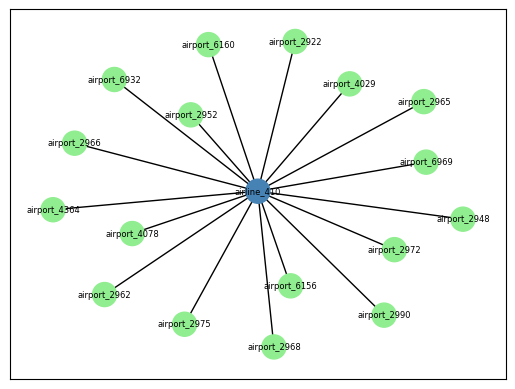

In [78]:
nx.draw_networkx(B.subgraph(['airline_410'] + list(B.neighbors('airline_410'))),
                 pos=nx.spring_layout(B.subgraph(['airline_410'] + list(B.neighbors('airline_410'))), seed=42),
                 node_color=['steelblue' if n == 'airline_410' else 'lightgreen' for n in B.subgraph(['airline_410'] + list(B.neighbors('airline_410'))).nodes()],
                 node_size=300, font_size=6, with_labels=True)

# Visualize the entire airline–airport bipartite network

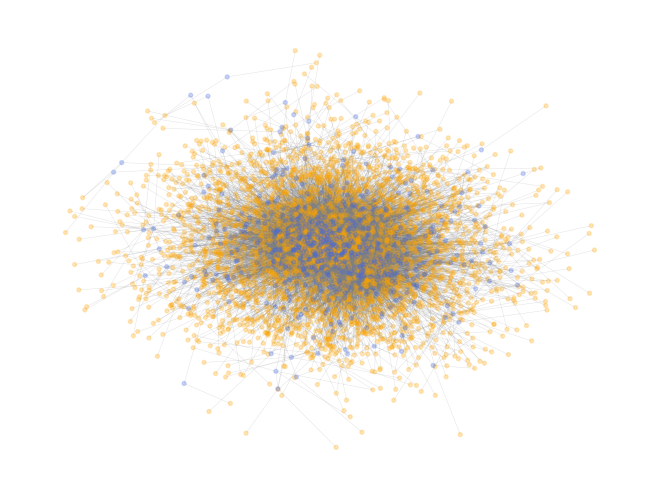

In [79]:
nx.draw(B, pos=nx.spring_layout(B, seed=42, iterations=30),
        node_color=['royalblue' if B.nodes[n]['bipartite'] == 0 else 'orange' for n in B.nodes()],
        node_size=8, edge_color='gray', alpha=0.25, width=0.3, with_labels=False)

# Degree Distribution

After viewing the graph, the next step is to analyze degree distribution before creating projections and applying the Island Method.

In this bipartite network, degree has two different meanings:

- Airline degree: How many unique airports an airline serves.
- Airport degree: How many unique airlines serve an airport.

For example, if Airline 410 connects to 20 airports, its degree is 20. If Kazan International Airport connects to 8 airlines, its degree is 8.

This helps me identify important airlines and airports before changing the network through projection.

The table will contain 3,734 rows: 546 airlines and 3,188 airports.

# Degree of Airlines

In [87]:
# Now I will display the top 10 most connected nodes in the airline–airport bipartite network.

degree_dict = dict(B.degree())

degree_df = pd.DataFrame(degree_dict.items(), columns=['Node ID', 'Degree'])

# It sorts the degrees of all nodes, including both airlines and airports.

degree_df.sort_values(by='Degree', ascending=False).head(10)

# Separate airline degree from airport degree

airline_degree_df = degree_df[degree_df['Node ID'].str.startswith('airline_')].sort_values('Degree', ascending=False)

airline_degree_df.head(10)

,Node ID,Degree
3276,airline_24,434
3651,airline_5209,431
3282,airline_137,386
3464,airline_3090,368
3340,airline_2009,354
3662,airline_5265,352
3294,airline_596,276
3632,airline_4951,258
3479,airline_3320,248
3509,airline_1758,219


# Degree of Airport

Next, I will calculate airport degrees separately to identify which airports are served by the most airlines.

In [89]:
airport_degree_df = degree_df[degree_df['Node ID'].str.startswith('airport_')].sort_values('Degree', ascending=False)

airport_degree_df.head(10)

,Node ID,Degree
407,airport_1382,109
419,airport_340,100
135,airport_3885,98
417,airport_1555,92
433,airport_507,86
139,airport_3077,84
323,airport_2188,83
149,airport_3316,83
274,airport_3364,81
191,airport_580,80


# Visualize the degree distributions
Before projection, I want to see whether most airlines have relatively few airport connections while a small number serve many airports.

The airline degree distribution is strongly right-skewed.

Most airlines serve relatively few airports, while a small number operate across extensive airport networks.

This suggests that airport coverage is concentrated among a limited number of highly connected airlines.

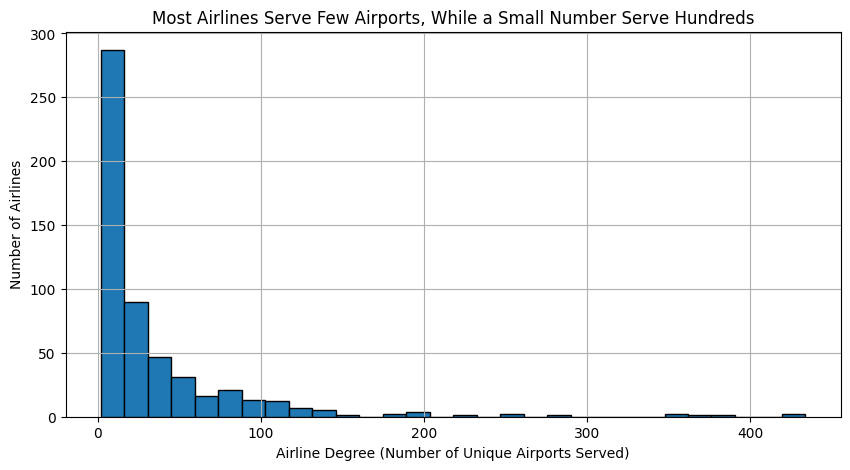

In [93]:
airline_degree_df['Degree'].hist(bins=30, figsize=(10, 5), edgecolor='black');
plt.title('Most Airlines Serve Few Airports, While a Small Number Serve Hundreds');
plt.xlabel('Airline Degree (Number of Unique Airports Served)');
plt.ylabel('Number of Airlines');
plt.show()

# Create the airline–airline Projection

Currently, the bipartite network B contains two types of nodes:
- Airlines: 546
- Airports: 3,188
In the airline–airline projection, I will keep only airline nodes.

Two airlines will be connected when they serve at least one common airport.

For example, if Airline A and Airline B both serve Kazan International Airport, the projected network will contain an edge between them.

And the edge weight represents the number of airports shared by two airlines.

Here, 34,759 connections means 34,759 unique pairs of airlines serve at least one common airport.

In [96]:
airline_projection = nx.bipartite.weighted_projected_graph(B, airline_nodes_df['Node ID'])

print("Airlines:", airline_projection.number_of_nodes(), "| Connections:", airline_projection.number_of_edges())

Airlines: 546 | Connections: 34759


# Visualize the airline–airline projection
Now I will visualize the projected network containing 546 airlines and 34,759 connections.

# Interpret the airline–airline projected network

The visualization shows that the airline–airline network is highly interconnected.

Here's what I observe:

- Dense center: Many airlines share airports with other airlines, creating a large concentration of connections.

- Outer nodes: Some airlines have fewer shared-airport connections and appear farther from the center.

- Isolated nodes: A few airlines appear completely disconnected from other airlines in the projection.

The visualization contains 546 airlines and 34,759 connections.

Some airlines have extensive overlap in their airport networks.

We also discovered that many airline pairs share only a few airports, as shown by your histogram.

But the projection has 34,759 connections, making it difficult to identify meaningful groups of airlines visually.

That brings us to the Island Method.

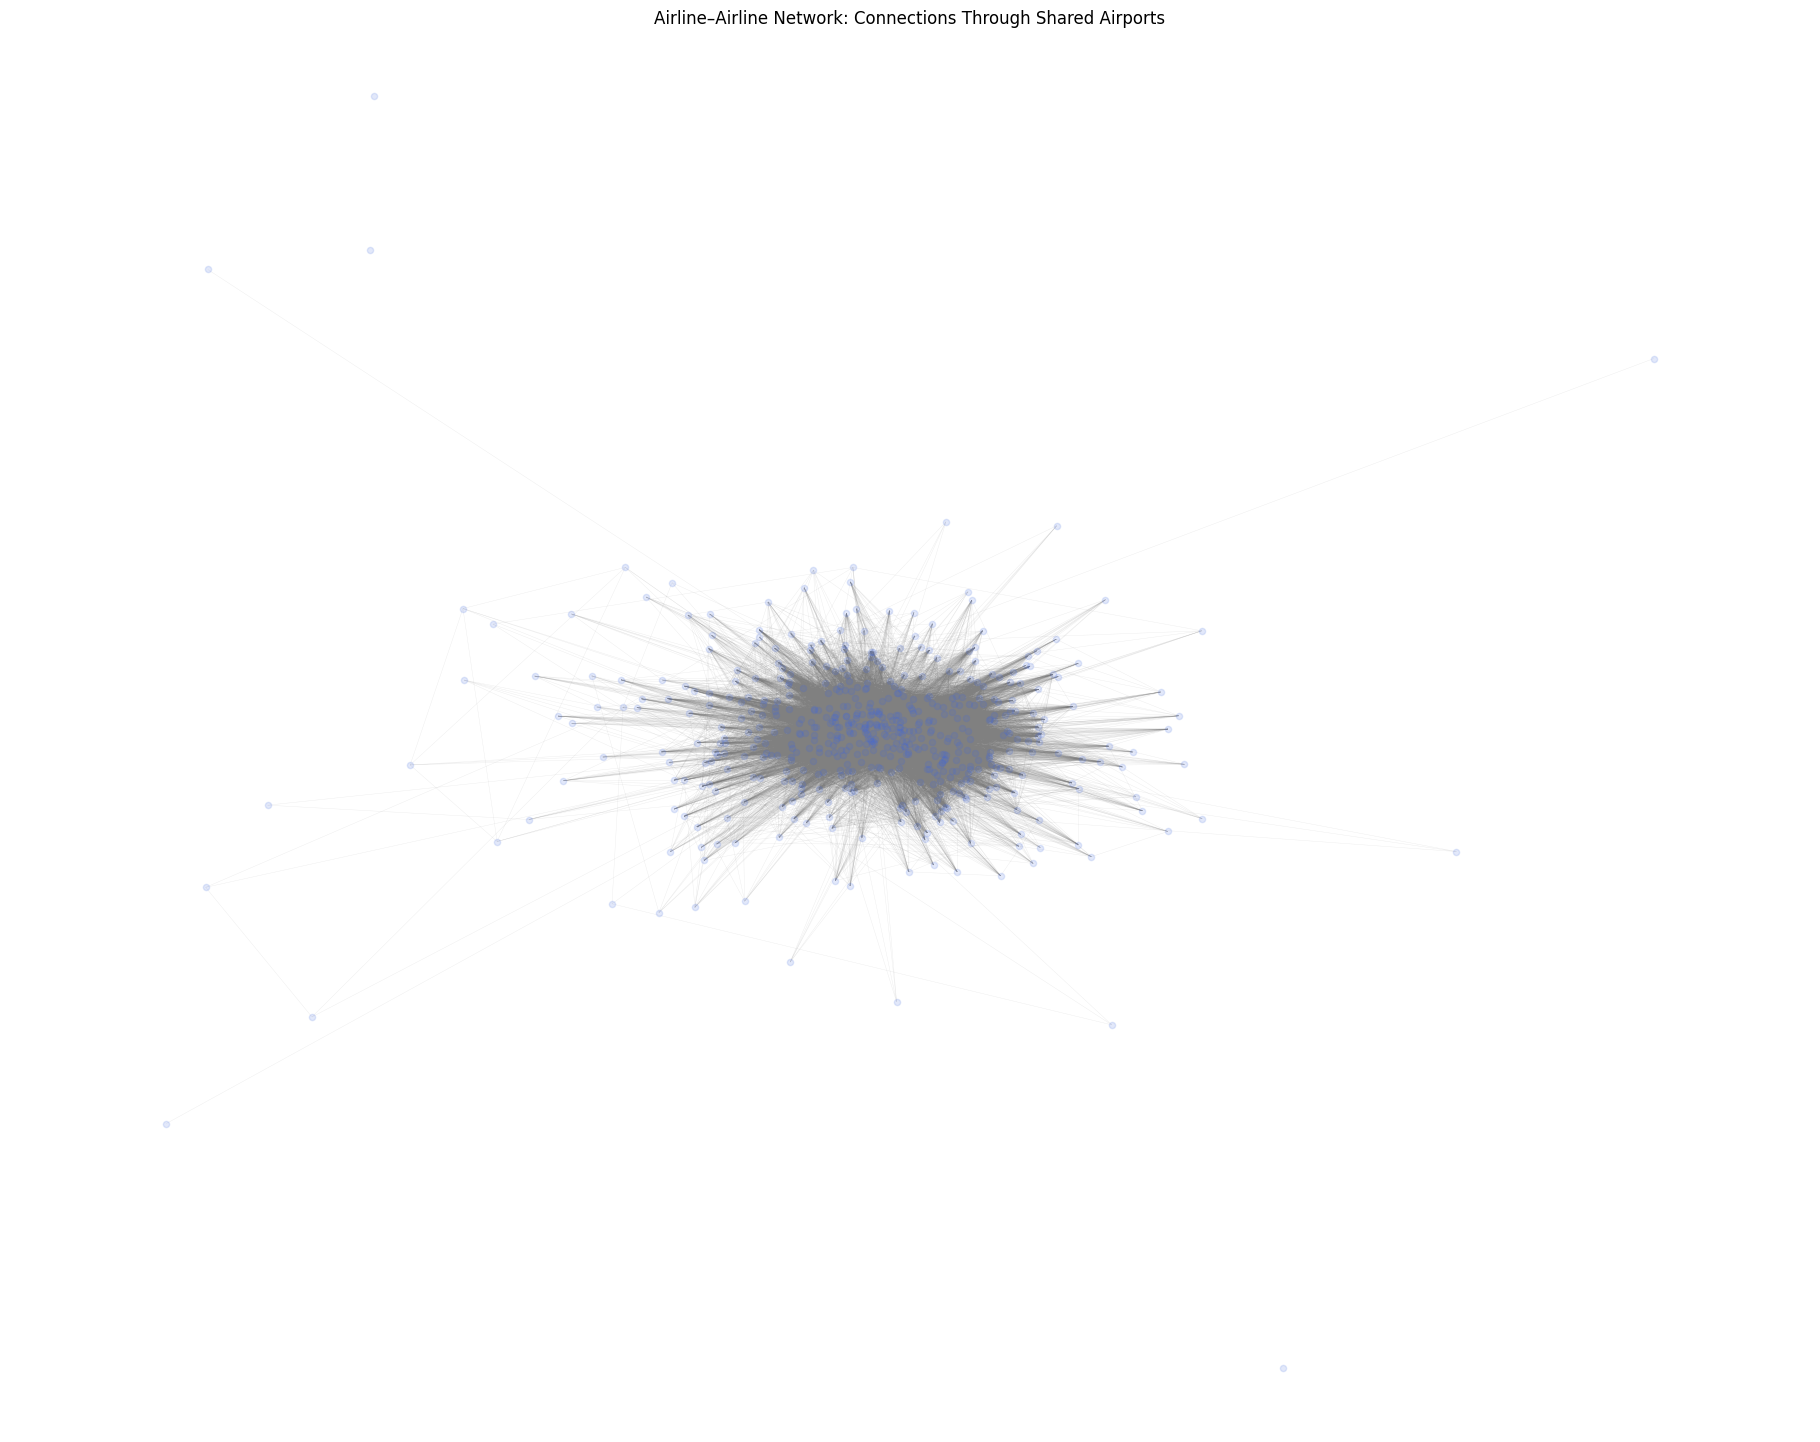

In [99]:
plt.figure(figsize=(18, 14));
nx.draw(airline_projection, pos=nx.spring_layout(airline_projection, seed=42, iterations=30), node_size=20, node_color='royalblue', edge_color='gray', alpha=0.15, width=0.3, with_labels=False);
plt.title('Airline–Airline Network: Connections Through Shared Airports');
plt.show()

# Prepare for the Island Method

We are applying the Island Method to the airline–airline projection

And the question is: When we remove weak airport-sharing connections, what groups of airlines remain connected?

In [102]:
print("Minimum shared airports:", min(nx.get_edge_attributes(airline_projection, 'weight').values()), "| Maximum shared airports:", max(nx.get_edge_attributes(airline_projection, 'weight').values()))

Minimum shared airports: 1 | Maximum shared airports: 339


In [106]:
shared_airports_df = pd.DataFrame([(u, v, d['weight']) for u, v, d in airline_projection.edges(data=True)], columns=['Airline 1', 'Airline 2', 'Shared Airports'])
shared_airports_df.sort_values('Shared Airports', ascending=False).head(10)

,Airline 1,Airline 2,Shared Airports
6702,airline_24,airline_5265,339
7800,airline_137,airline_3090,293
6669,airline_24,airline_5209,283
15876,airline_2009,airline_5209,275
6915,airline_24,airline_2009,270
34078,airline_5209,airline_5265,253
6583,airline_24,airline_3090,252
6693,airline_24,airline_137,248
15900,airline_2009,airline_5265,245
15801,airline_2009,airline_3090,240


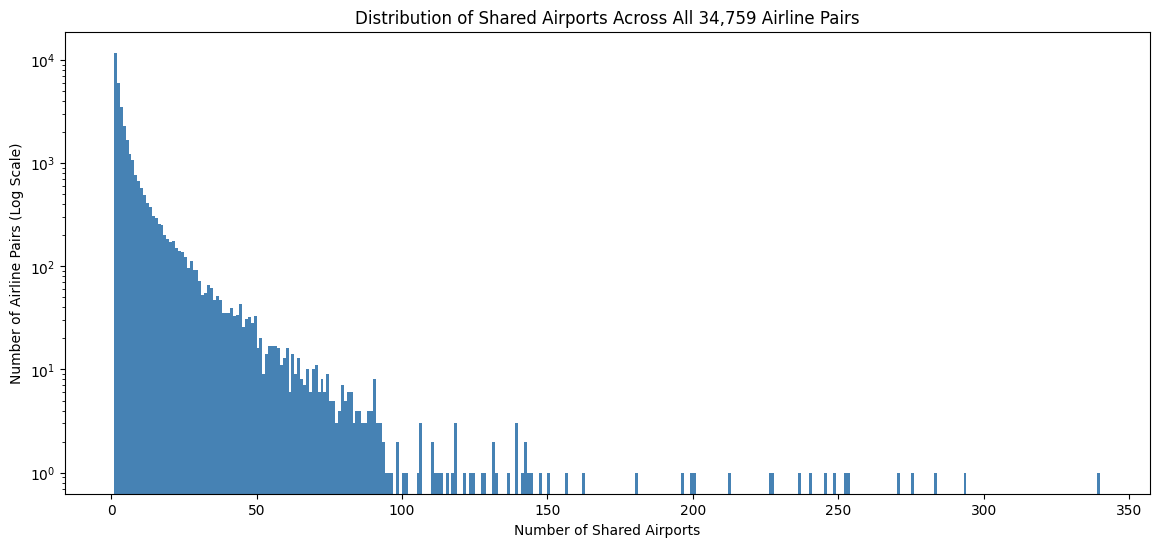

In [107]:
plt.figure(figsize=(14, 6));
plt.hist(shared_airports_df['Shared Airports'], bins=range(1, 341), color='steelblue', edgecolor='none');
plt.yscale('log'); plt.xlabel('Number of Shared Airports');
plt.ylabel('Number of Airline Pairs (Log Scale)');
plt.title('Distribution of Shared Airports Across All 34,759 Airline Pairs');
plt.show()

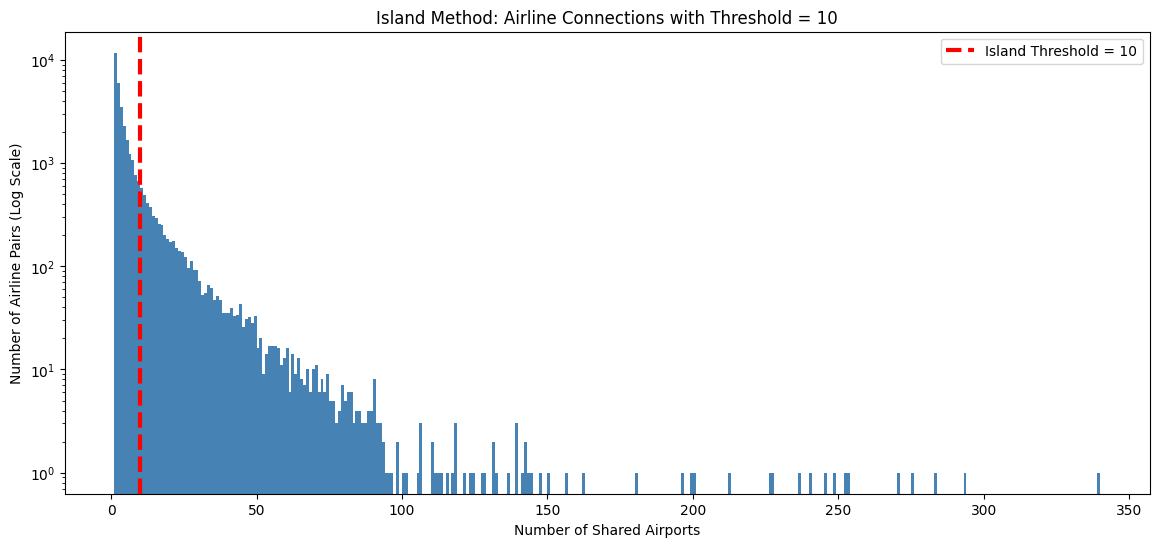

In [108]:
plt.figure(figsize=(14, 6)); plt.hist(shared_airports_df['Shared Airports'], bins=range(1, 341), color='steelblue'); plt.yscale('log'); plt.axvline(x=10, color='red', linestyle='--', linewidth=3, label='Island Threshold = 10'); plt.xlabel('Number of Shared Airports'); plt.ylabel('Number of Airline Pairs (Log Scale)'); plt.title('Island Method: Airline Connections with Threshold = 10'); plt.legend(); plt.show()

# Creating first airline island network

Keeping only connections between airlines sharing at least 10 airports.

And trying to answer: How many airlines and connections remain when we focus on stronger airport-sharing relationships?


In [110]:
airline_island = nx.edge_subgraph(airline_projection, [(u, v) for u, v, d in airline_projection.edges(data=True) if d['weight'] >= 10]).copy()

print("Original network:", airline_projection.number_of_nodes(), "airlines,", airline_projection.number_of_edges(), "connections | Filtered network:", airline_island.number_of_nodes(), "airlines,", airline_island.number_of_edges(), "connections")

Original network: 546 airlines, 34759 connections | Filtered network: 306 airlines, 5916 connections


In [111]:
print("Number of islands:", nx.number_connected_components(airline_island))

Number of islands: 3


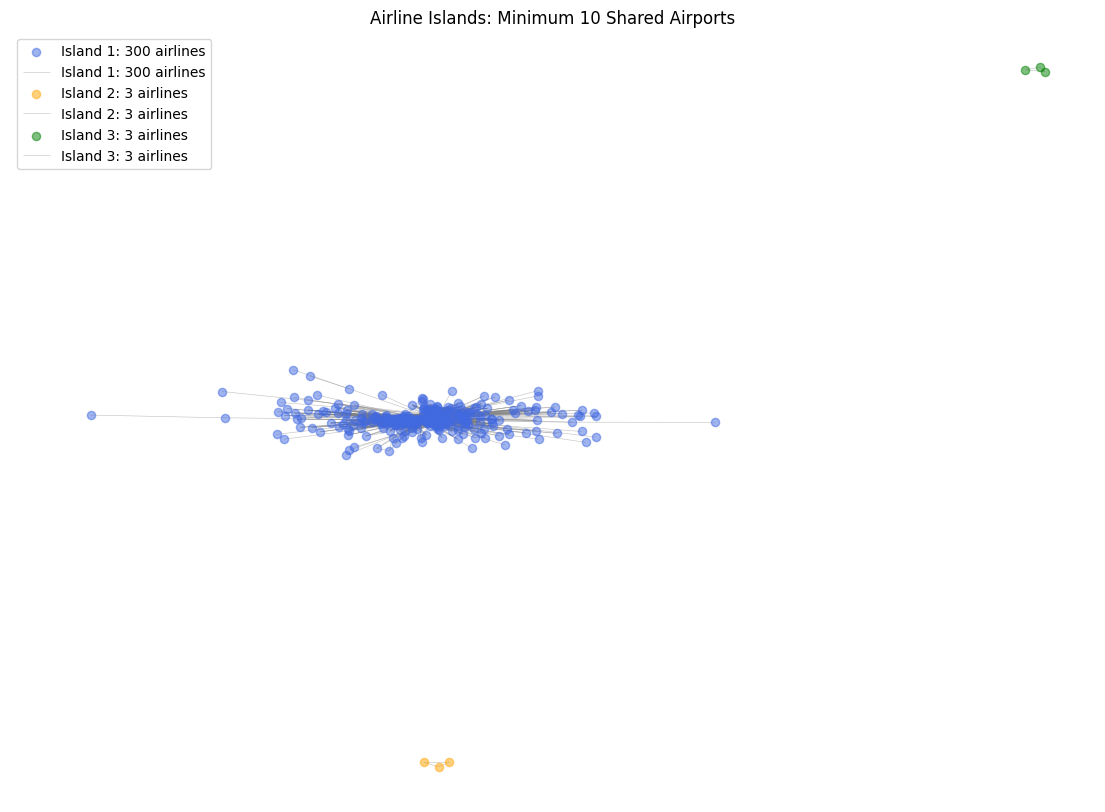

In [114]:
plt.figure(figsize=(14, 10)); components = sorted(nx.connected_components(airline_island), key=len, reverse=True); pos = nx.spring_layout(airline_island, seed=42); [nx.draw_networkx(airline_island.subgraph(c), pos=pos, node_color=['royalblue', 'orange', 'green'][i], node_size=35, edge_color='gray', alpha=0.5, width=0.4, with_labels=False, label=f'Island {i+1}: {len(c)} airlines') for i, c in enumerate(components)]; plt.title('Airline Islands: Minimum 10 Shared Airports'); plt.legend(); plt.axis('off'); plt.show()

# Extract the largest island using NetworkX

We already know that 306 airlines and 5,916 connections remain across three islands. Now we want to determine how much of that network belongs to the largest island.

In [116]:
largest_island = airline_island.subgraph(max(nx.connected_components(airline_island), key=len)).copy()

print("Largest island:", largest_island.number_of_nodes(), "airlines,", largest_island.number_of_edges(), "connections")

Largest island: 300 airlines, 5910 connections


# Visualize the largest airline island using NetworkX
Now that we have extracted largest_island, let's visualize its network structure.

Research question: How are airlines connected within the largest island when each connection represents at least 10 shared airports?

Interpretation:

Dense center: Many airlines share at least 10 airports with several other airlines in the island.

Outer nodes: Some airlines share at least 10 airports with only one or a few other airlines.

Long connecting lines: These represent relationships in the network layout, not geographic distances.

One connected island: Every airline in this graph can reach every other airline through a sequence of connections.

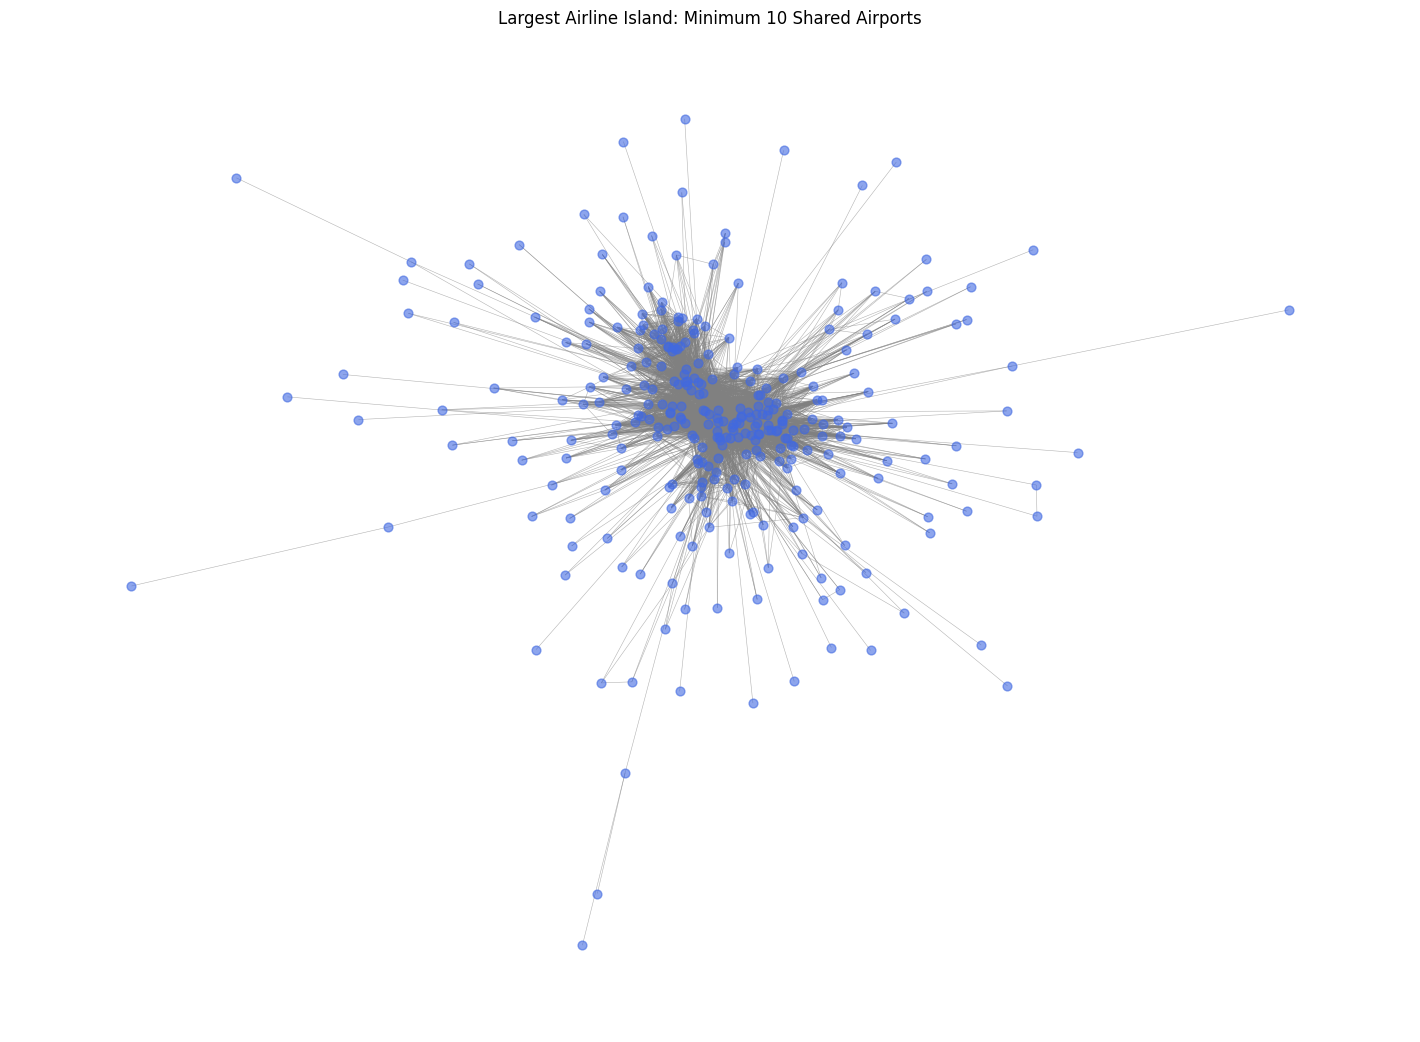

In [118]:
plt.figure(figsize=(14, 10));
nx.draw(largest_island, pos=nx.spring_layout(largest_island, seed=42), node_size=40, node_color='royalblue', edge_color='gray', width=0.4, alpha=0.6, with_labels=False);
plt.title('Largest Airline Island: Minimum 10 Shared Airports');
plt.show()

Which airlines are the most connected within the largest island?

The graph suggests that some airlines have many more connections than others. We can identify them using degree centrality.

In our original bipartite network, airline degree counted the number of airports served.

In this airline island, degree counts the number of other airlines sharing at least 10 airports with that airline.

# Identify the 10 most connected airlines

Airline 137 has the highest degree (183). This means it shares at least 10 airports with 183 other airlines within the largest island.

Airline 3090 follows closely with 181 connections.

These airlines occupy highly connected positions in the filtered network.

Importantly, a high degree here does not mean an airline operates more flights. It means the airline shares at least 10 airports with more other airlines.

In [119]:
pd.DataFrame(largest_island.degree(), columns=['Airline ID', 'Degree']).sort_values('Degree', ascending=False).head(10)

,Airline ID,Degree
40,airline_137,183
150,airline_3090,181
160,airline_3320,162
51,airline_596,160
35,airline_24,158
237,airline_4951,151
56,airline_1355,145
252,airline_5209,144
89,airline_2183,139
70,airline_751,136


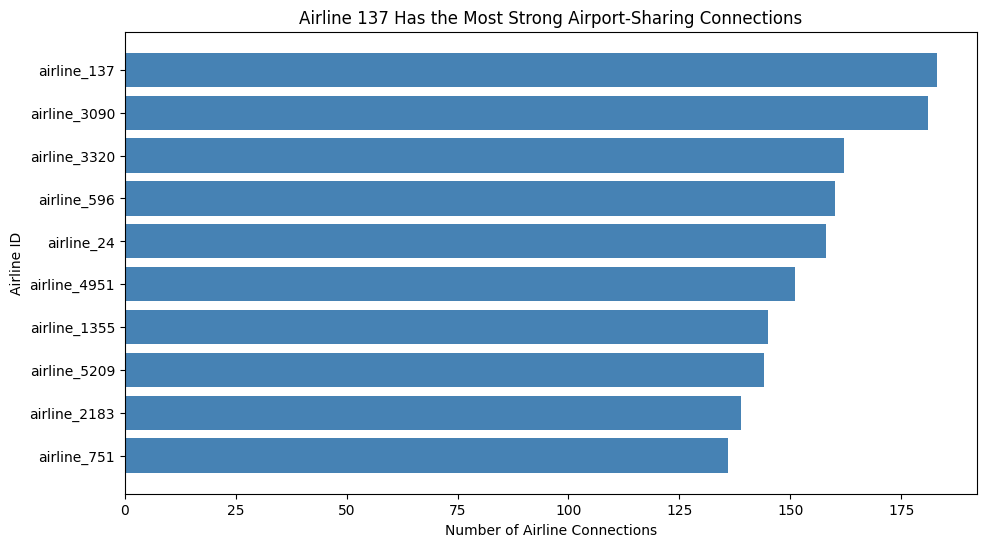

In [120]:
top10_degree = pd.DataFrame(largest_island.degree(), columns=['Airline ID', 'Degree']).nlargest(10, 'Degree');
plt.figure(figsize=(11, 6)); plt.barh(top10_degree['Airline ID'], top10_degree['Degree'], color='steelblue');
plt.gca().invert_yaxis(); plt.xlabel('Number of Airline Connections');
plt.ylabel('Airline ID');
plt.title('Airline 137 Has the Most Strong Airport-Sharing Connections');
plt.show()

# Final Conclusion: Airline Network Analysis

### Conclusion

In this analysis, I used the OpenFlights dataset to investigate relationships between airlines and airports using Social Network Analysis in Python and NetworkX.

**1. Bipartite Network Analysis**

I constructed a bipartite network consisting of 546 airlines and 3,188 airports. The network contained 19,039 unique airline–airport connections. This helped me understand which airlines serve the most airports and which airports are served by the most airlines.

**2. Airline–Airline Projection**

I created a weighted airline–airline projection to investigate relationships between airlines based on shared airports.

The projected network contained 546 airlines and 34,759 connections. The number of shared airports between airline pairs ranged from 1 to 339.

The distribution showed that most airline pairs share relatively few airports, while a smaller number have substantial airport overlap.

**3. Island Method**

To identify stronger airline relationships, I applied the Island Method using a minimum threshold of 10 shared airports.

After applying the threshold:

- Airlines decreased from 546 to 306.
- Connections decreased from 34,759 to 5,916.
- Approximately 83% of connections were removed.
- The remaining network formed three connected islands.

These findings suggest that many airline relationships involve limited airport overlap, while a smaller set of airlines maintains stronger shared-airport connections.

**4. Largest Island Analysis**

I examined the largest island using NetworkX visualization and degree analysis.

The visualization revealed a densely connected center surrounded by more peripheral airlines.

Airline 137 had the highest degree (183), followed by Airline 3090 (181) and Airline 3320 (162).

This indicates that Airline 137 shares at least 10 airports with 183 other airlines within the largest island, making it the most connected airline under the selected threshold.

### Overall Findings

The analysis demonstrates how bipartite projection and the Island Method can reveal meaningful structures within a complex airline network.

The airline–airline projection helped identify overlapping airport coverage, while the Island Method reduced network complexity and revealed three connected groups of airlines.

The largest island contained a densely interconnected core, suggesting that some airlines have substantially broader airport-sharing relationships than others.

**Overall, I found that airline airport-sharing relationships are unevenly distributed, with a relatively small number of highly connected airlines occupying central positions in the filtered network.**